
Lecture link(@1:59:00) [Till point 4]: https://www.scaler.com/meetings/i/dsml-advanced-svm-2-2/archive

lecture Link [Point 5 onwards]: https://www.scaler.com/meetings/i/dsml-advanced-naive-bayes-2/archive

## Content

1. Introduction
2. Understanding our spam classifier data

3. Mathematical intuition
 - Calculating class priors
4. Naive assumption
 - Calculating likelihoods
 - Final equation

5. Train time of Naive Bayes

6. Test time of Naive Bayes

7. Complexity of Naive Bayes

8. Laplace Smoothing

9. Hyperparameter tuning

10. Impact of imbalance

11. Underflow problem

12. Feature Importance and Interpretability

13. Multinomial Naive Bayes


## **Imagine you are Data Scientist at Google**

You are working on **Spam Classification model**

#### (Interaction) Question: What do you think will be good for classifying spam from not spam mails?

We can say that that email content will be one of the useful things in classfying the email.

Now, let's focus on the email text.

#### Q. Which one one of the following do you think is a spam?

1. Mail 1 : "I, Nigerian prince need your help. Send money"
2. Mail 2: "Meeting scheduled for 5 pm. Kindly revert"


Obviously, Mail 1 is a spam mail.

<br>

#### Q. How did you come to conclusion that Mail 1 is Spam mail ?

Notice that there are few keywords which are specific to Spam mail only.

- For example:
"Nigerian prince", "lottery", "million dollars" all points to that mail is more likely to be spam.

<br>


#### Q. What if we had basic approach that classifies spam from ham based on all these **keywords**?


Let's look at a technique which works on the same principles i.e. Naive Bayes.










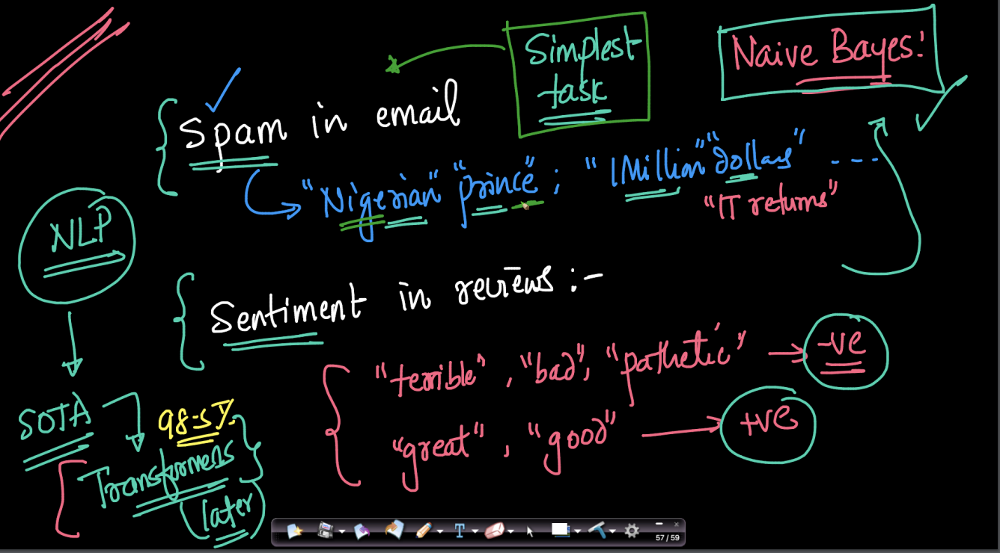

#### Understanding our spam classifier data

#### Q. What do we have in our data?

For our data, we have  
1. n number of texts which contains words
2. class label i.e.
    - Spam will be (class 1 or y = 1)
    - Ham (or Not spam) will be (class 0 or y = 0)

## **Q. What do we understand by text?**

The text body of email is essentially a **sequence of words**.

We can write $text_i$, as $ text_{i} = w_{1}^i, w_{2}^i, w_{3}^i, ..., w_{d}^i $


where, d -> length of text $email_i$.

**Note:** The number of words in text1 **may or may not be equal** to the number of words in text2


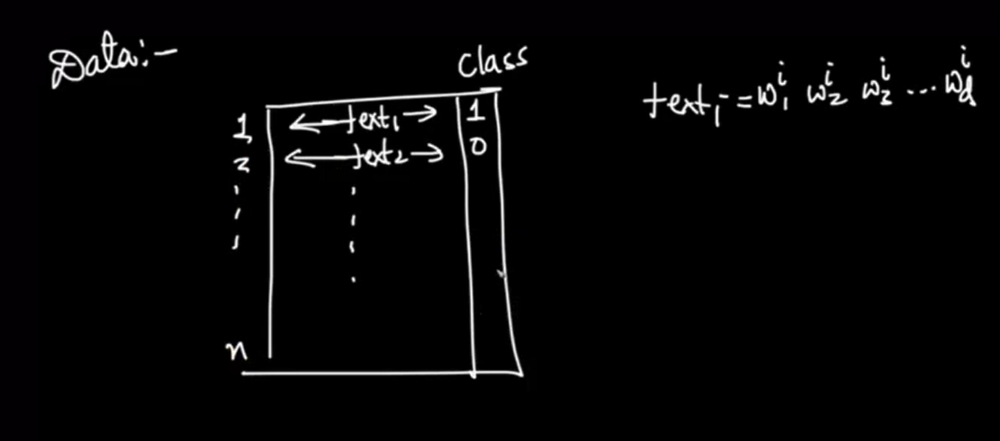

Let's look at our data now

In [ ]:
# Importing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

#### Let's load the data

In [ ]:
!gdown 1d4VFxFxPqBpKoUuH51PQ8PYrFBmPCnH8

Downloading...
From: https://drive.google.com/uc?id=1d4VFxFxPqBpKoUuH51PQ8PYrFBmPCnH8
To: /content/spam_clean.csv
100% 484k/484k [00:00<00:00, 133MB/s]


#### Q. How do we make sure that the system knows our data is in English?
- We can set the value of parameter **encoding** as `latin-1` to  explicitly mention that the letters in the texts are english.

In [ ]:
df = pd.read_csv('spam_clean.csv', encoding='latin-1')
df.head()

,type,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


#### Performing EDA

Let's see the distribution of class labels


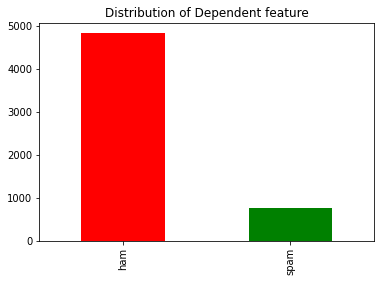

In [ ]:
freq = pd.value_counts(df["type"], sort= True)
freq.plot(kind= 'bar', color= ["red", "green"])
plt.title('Distribution of Dependent feature')
plt.show()

**Observation**:

As we can see, the number of texts which are spam are quite less as compared to the texts which are ham (or not spam)

Clearly, we have an **imbalanced data**!


# **Preprocessing data**

####1. Tokenization

Let's first split the sentence into it's constituent words (i.e. individual **tokens**)

This is also known as **tokenization**

<br>


Lets take an example to understand this:

Sentence:  **"Hi my name is Anthony Gonsalves."**

After splitting the sentence, we get

List: ["my", 'Hi", "is", "Gonsalves", "Anthony", "name", "."]




### 2. Lower Casing

#### Q. Given two setences, Should they be treated as different or same?

Sentence 1 : Let's go to the mall

Sentence 2: let's GO to the MALL

Ans: **No!**. We don't want to treat these **intances/ sentences** as different one.

<br>


#### Q. How do we resolve this?

One way to avoid multiple instances of same word/sentence is to **convert them to lower case**.







#### 3. Removing punctuations

```
Mail 1 : "I, Nigerian price need your help. Send money"

Mail 2: "Meeting scheduled for 5 pm. Kindly revert"
```

In order to differentiate between spam v.s ham,
- we focused on **keywords** which helped us in differentiating.

<br>

#### Q. Do we need to look at punctuations while classfying mails?

Ans: No. As our focus is keyword which can help us classify.

Hence, we will be removing these using the **Regular Expressions**.


#### 4. Stop Words

#### Q. Do you think words like a, an, the, of are useful in classifying spam from ham ?

These words (a, an, the, do, it, she, it etc) are called **stop words**
- These are some of the most common, short function words and
- They add little or no **real meaning** to our text as  they carry **very little** useful information.

So, They can **safely be ignored without sacrificing the meaning of the sentence**.

Not to mention, parsing through these words would make it more **computationally expensive** for no reason.

We remove these words from our data.


Do NOTE: But there are tasks like translation, Que-Ans based system  where we cannot remove stop words.



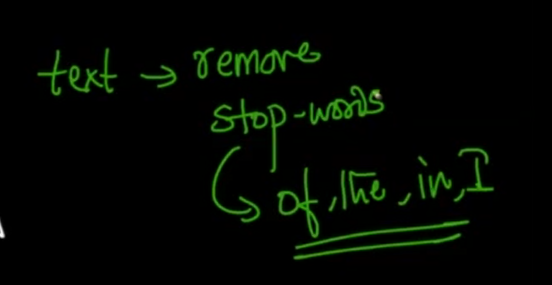

#### Q. Wouldn't removing stop words lead to grammatical errors?
**Yes**. It will.

But since to understand context from keywords, grammer is not important hence we use stopwords removal technique

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/25983/

Lets implement all of these text processing using the  [NLTK](https://www.nltk.org/) library

In [ ]:
# Libraries for text processing
import re, nltk
nltk.download('punkt')
nltk.download('stopwords')
from nltk import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

def clean_tokenized_sentence(s):
    """Performs basic cleaning of a tokenized sentence"""
    cleaned_s = ""  # Create empty string to store processed sentence.
    words = nltk.word_tokenize(s)
    for word in words:
        # Convert to lowercase #
        c_word = word.lower()
        # Remove punctuations #
        c_word = re.sub(r'[^\w\s]', '', c_word)
        # Remove stopwords #
        if c_word != '' and c_word not in stopwords.words('english'):
            cleaned_s = cleaned_s + " " + c_word    # Append processed words to new list.
    return(cleaned_s.strip())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Calling the `clean_tokenized_sentence(s)` function onto each text in our dataset using the **apply** method, and storing them in a new column, `cleaned_message`

In [ ]:
df["cleaned_message"] = df["message"].apply(clean_tokenized_sentence)
df.head(10)

,type,message,cleaned_message
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah nt think goes usf lives around though
5,spam,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling 3 week word back like fun ...
6,ham,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,ham,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,spam,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,spam,Had your mobile 11 months or more? U R entitle...,mobile 11 months u r entitled update latest co...


**QUIZ**
```
What will be the stopwords in "We are the best." ?

1. We, are, the
2. We, are, best
3. are, the
4. the

```
**ANSWER**
1. We, are, the



## Q. Do some words tend to occur more frequently in ham texts than in spam texts?
Yes. Recall we talked about some keywords being specific to spam or ham messages.

Words like "Nigerian prince", "lottery", "prize", etc tend to occur more in spam messages than in ham.

<br>

#### Q. How can we look at the Word frequencies (number of times each word occurs) in a given text?

In order to get the frequency of occurrence of the words in a given text, we employ the use of `Counter` from the `collections` library.

The **Counter()** counts the number of time each word occurs after splitting.


<br>

#### Lets see the most occuring words in ham messages
#### Q. How do we get the top 20 words that occur the most frequently in ham texts?

We need to first filter the non-spam rows,
- then Obtain the cleaned message
- followed by Splitting the messages into words
- and finally Invoking the Counter() object

 First, let's filter the texts that are of type = 'ham'



In [ ]:

ham = df[df['type'] == 'ham']
ham

,type,message,cleaned_message
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah nt think goes usf lives around though
6,ham,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
...,...,...,...
5565,ham,Huh y lei...,huh lei
5568,ham,Will Ì_ b going to esplanade fr home?,ì_ b going esplanade fr home
5569,ham,"Pity, * was in mood for that. So...any other s...",pity mood suggestions
5570,ham,The guy did some bitching but I acted like i'd...,guy bitching acted like interested buying some...


Since we only wish to look at our preprocessed text, we get the cleaned_message column

In [ ]:
ham = ham['cleaned_message']
ham

0       go jurong point crazy available bugis n great ...
1                                 ok lar joking wif u oni
3                     u dun say early hor u c already say
4               nah nt think goes usf lives around though
6          even brother like speak treat like aids patent
                              ...                        
5565                                              huh lei
5568                         ì_ b going esplanade fr home
5569                                pity mood suggestions
5570    guy bitching acted like interested buying some...
5571                                       rofl true name
Name: cleaned_message, Length: 4825, dtype: object

We club all the texts for Ham

In [ ]:

ham = " ".join(ham)
ham

'go jurong point crazy available bugis n great world la e buffet cine got amore wat ok lar joking wif u oni u dun say early hor u c already say nah nt think goes usf lives around though even brother like speak treat like aids patent per request melle melle oru minnaminunginte nurungu vettam set callertune callers press 9 copy friends callertune gon na home soon nt want talk stuff anymore tonight k cried enough today searching right words thank breather promise wont take help granted fulfil promise wonderful blessing times date sunday oh k watching eh u remember 2 spell name yes v naughty make v wet fine thatåõs way u feel thatåõs way gota b seriously spell name iûm going try 2 months ha ha joking ì_ pay first lar da stock comin aft finish lunch go str lor ard 3 smth lor u finish ur lunch already ffffffffff alright way meet sooner forced eat slice really hungry tho sucks mark getting worried knows sick turn pizza lol lol always convincing catch bus frying egg make tea eating mom left di

Now Splitting the entire text into words

In [ ]:

ham = ham.split()
ham

['go',
 'jurong',
 'point',
 'crazy',
 'available',
 'bugis',
 'n',
 'great',
 'world',
 'la',
 'e',
 'buffet',
 'cine',
 'got',
 'amore',
 'wat',
 'ok',
 'lar',
 'joking',
 'wif',
 'u',
 'oni',
 'u',
 'dun',
 'say',
 'early',
 'hor',
 'u',
 'c',
 'already',
 'say',
 'nah',
 'nt',
 'think',
 'goes',
 'usf',
 'lives',
 'around',
 'though',
 'even',
 'brother',
 'like',
 'speak',
 'treat',
 'like',
 'aids',
 'patent',
 'per',
 'request',
 'melle',
 'melle',
 'oru',
 'minnaminunginte',
 'nurungu',
 'vettam',
 'set',
 'callertune',
 'callers',
 'press',
 '9',
 'copy',
 'friends',
 'callertune',
 'gon',
 'na',
 'home',
 'soon',
 'nt',
 'want',
 'talk',
 'stuff',
 'anymore',
 'tonight',
 'k',
 'cried',
 'enough',
 'today',
 'searching',
 'right',
 'words',
 'thank',
 'breather',
 'promise',
 'wont',
 'take',
 'help',
 'granted',
 'fulfil',
 'promise',
 'wonderful',
 'blessing',
 'times',
 'date',
 'sunday',
 'oh',
 'k',
 'watching',
 'eh',
 'u',
 'remember',
 '2',
 'spell',
 'name',
 'yes',


Finding the top 20 words mostly used in Ham

In [ ]:
counter_ham = Counter(ham).most_common(20)
counter_ham

[('u', 1004),
 ('nt', 360),
 ('gt', 318),
 ('lt', 316),
 ('2', 309),
 ('get', 303),
 ('ok', 279),
 ('go', 248),
 ('got', 244),
 ('ur', 241),
 ('know', 236),
 ('like', 231),
 ('call', 231),
 ('good', 229),
 ('come', 227),
 ('time', 197),
 ('day', 192),
 ('love', 191),
 ('4', 172),
 ('going', 169)]

**Note:** Counter() object returns a **dictionary**, with word as the key, and it's count as the respective value.

But when we call the `most_common()` method, it transforms the dictonary to  a tuple and returns a list of tuples as the result.

Alternatively, we could've clubbed these steps into one line as

In [ ]:
# counter_ham = Counter(" ".join(df[df['type']=='ham']["cleaned_message"]).split()).most_common(20)

Visualizing the 20 words and there number of Occurence

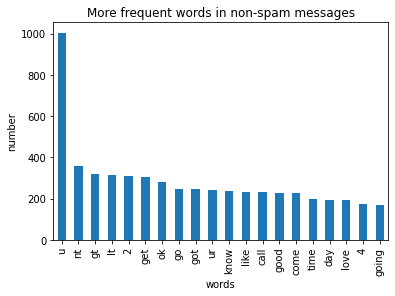

In [ ]:
# load the results as a pandas dataframe in order to plot
df_ham = pd.DataFrame(counter_ham)

# Renaming the columns in this dataframe
df_ham = df_ham.rename(columns={0:"words in non-spam", 1:"count"})

# Plotting the data
df_ham.plot.bar(legend = False)
y_pos = np.arange(len(df_ham["words in non-spam"]))
plt.xticks(y_pos, df_ham["words in non-spam"])
plt.title('More frequent words in non-spam messages')
plt.xlabel('words')
plt.ylabel('number')
plt.show()

We can see words like "love", "time", "got", "go", etc tend to occur a lot in ham messages.

Similarily, we plot the data for 20 most common words in spam texts.

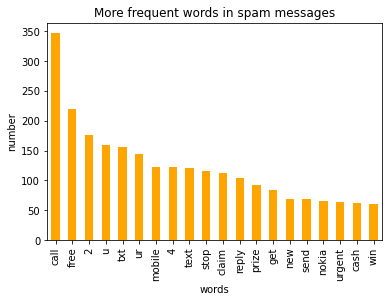

In [ ]:
# Invoking the Counter() object on a list of words occuring in the "cleaned_message" column of spam texts, joined together
counter_spam = Counter(" ".join(df[df['type']=='spam']["cleaned_message"]).split()).most_common(20)

# load the results as a pandas dataframe in order to plot
df_spam = pd.DataFrame(counter_spam)

# Renaming the columns in this dataframe
df_spam = df_spam.rename(columns={0:"words in spam", 1:"count_"})

# Plotting the data
df_spam.plot.bar(legend = False, color = 'orange')
y_pos = np.arange(len(df_spam["words in spam"]))
plt.xticks(y_pos, df_spam["words in spam"])
plt.title('More frequent words in spam messages')
plt.xlabel('words')
plt.ylabel('number')
plt.show()

We can see that there is a difference of words contained in spam and ham messages.

Spam messages have words like, "call", "free", "mobile", "claim", "prize", etc.


Converting the categorical feature `type` into a numerical feature by mapping spam value as 1, and ham values as 0.

In [ ]:
df["type"] = df["type"].map({'spam':1,'ham':0})

Performing the `train_test_split`

In [ ]:
from sklearn.model_selection import train_test_split

df_X_train, df_X_test, y_train, y_test = train_test_split(df['cleaned_message'], df['type'], test_size=0.25, random_state=42)
print([np.shape(df_X_train), np.shape(df_X_test)])

[(4179,), (1393,)]


# **Mathematical Intuition**



#### Q. How do we go about predicting whether a given $text_i$, is spam (y=1) or not (y=0)?

In order to do so, we calculate two probability values
1. Probabilty that given text is spam $ P(y=1|text)$
2. Probabilty that given text is ham $P(y=0|text) $

Out of the two Probabilities, Whichever value we find to be **higher**, we get our answer accordingly.

<br>

#### Q. How can we find the value of $P(y=1|text)$ and $P(y=0|text)$?
Recall how text is just some sequence of d words

Hence we can say,
- "Probability that text i is a spam given that words $w_{1}^i$ **AND** $w_{2}^i$ **AND** $w_{3}^i$ **AND**  ... **AND** $w_{d}^i$ exist in our text".

 - Therefore $ P_{i}(y=1|text_{i})$ can be written as $ P_{i}(y=1|w_{1}^i, w_{2}^i, w_{3}^i, ..., w_{d}^i) $ <br>
 - Similarly, $ P_{i}(y=0|text_{i})$ can be written as $ P_{i}(y=0|w_{1}^i, w_{2}^i, w_{3}^i, ..., w_{d}^i) $ <br>





#### Q. How can we find the value of $ P_{i}(y=1|w_{1}^i, w_{2}^i, w_{3}^i, ..., w_{d}^i) $?

Since this is **conditional probability**, perhaps we can apply **Baye's theorm**?

> Recall Baye's theorm from Probability/Stats lecture: **[PREREAD]**<br>
- if A and B are some events then
$P(A|B) = \frac{P(B|A)*P(A)}{P(B)}$<br>
where, <br>
P(A|B)	=	probability of A given B is true<br>
P(B|A)	=	probability of B given A is true<br>
P(A), P(B)	=	the independent probabilities of A and B

<br>

Now Assuming X be the event that words $w_{1}^i, w_{2}^i, w_{3}^i, ..., w_{d}^i$ exist in our text.

This means $ P_{i}(y=1|w_{1}^i, w_{2}^i, w_{3}^i, ..., w_{d}^i) = P_{i}(y=1|X)$

<br>

- According to Baye's theorm, we have, <br>
$P_{i}(y=1|X) = \frac{P(X|y=1)*P(y=1)}{P(X)} $

Let k = P(X) <br>

- $P_{i}(y=1|X) = \frac{P(X|y=1)*P(y=1)}{k}$

- Similarily, we get equation for P(y=0|X) as:- <br>
$P_{i}(y=0|X) = \frac{P(X|y=0)*P(y=0)}{P(X)} = \frac{P(X|y=0)*P(y=0)}{k}$

<br>

#### Q. What do we do after calculating the values of $P_{i}(y=1|X)$ and $P_{i}(y=0|X)$?

As we discussed earlier, we **compare the values** of $P_{i}(y=1|X)$ and $P_{i}(y=0|X)$.

- Since, $P(X) = P(w_1^i, w_2^i, ..., w_d^i) = k$ will be a constant in both cases, we can **remove it** while comparing.

<br>


Thus we are left with $P_{i}(y=1|X) = P(X|y=1)*P(y=1)$ and $P_{i}(y=0|X) = P(X|y=0)*P(y=0)$
- now, if we find the values of these 4 terms of probabilities we're done.


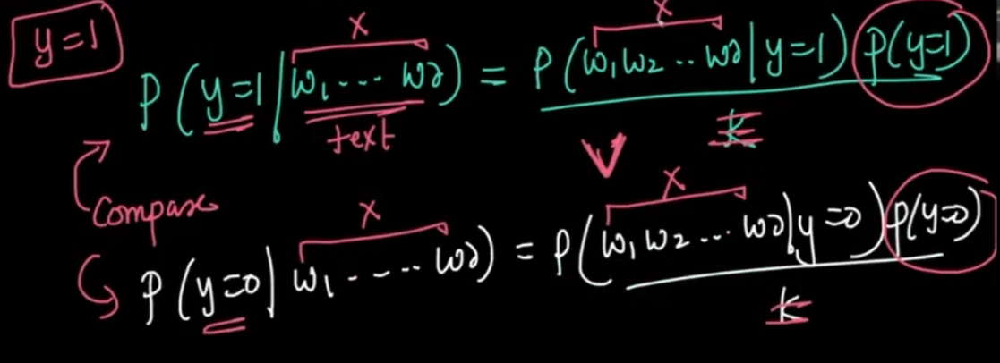

**Quiz**
```
Let's say:
the probability of dangerous fires are rare (1%)
but smoke is fairly common (10%) due to barbecues,
and 90% of dangerous fires make smoke
Can you find the probability of dangerous Fire when there is Smoke?

1. 0.09
2. 0.9
3. 0.3
4. 0.1

```
**Answer:**
1. 0.09

**Explanation:**

$P(Dangerous Fire|Smoke) = \frac{P(Dangerous Fire) * P(smoke|Dangerous Fire)}{P(smoke)}$
- $P(Dangerous Fire|Smoke) = \frac{0.01 * 0.9}{0.1} = 0.09$



# Q. How can we get the values of P(y=1) and P(y=0)?

In our training data, our dependent variable $y_i$ has two values 1 and 0

- Hence, in order to calculate $P(y=1)$,
 - we **find the number of train points where occcurence of y=1**
 - and divide it by the **total number of train points**


Similarily, we can calculate $P(y=0)$
- by dividing **the number of train points where occcurence of y=0**
- to the **total number of train points** to get the probability for y=0.

<br>

**Note:** These $P(y=0)$ and $P(y=1)$ are called as the **class priors**.



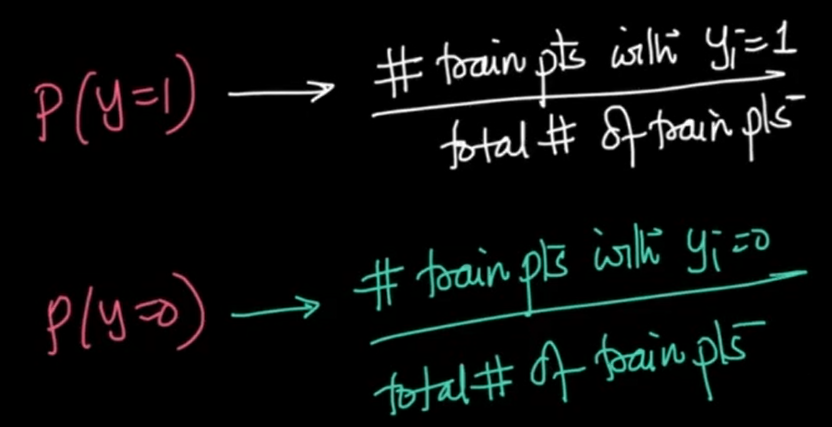

**ASSESSMENTS COVERED**

CODING QUESTION
- https://www.scaler.com/hire/test/problem/25986/

- https://www.scaler.com/hire/test/problem/14813/ (HOLD)

# **Naive Assumption**



#### Q. What about 𝑃(𝑋|𝑦=1) and 𝑃(𝑋|𝑦=0)?
Lets first understand for $𝑃(𝑋|𝑦=1)$

It means that
- "given that the email is spam (y=1)
- then what is the probability that the email contains the words $w_{1}^i$ **and** $w_{2}^i$ **and** $w_{3}^i$ **and** ... **and** $w_{d}^i$



<br>

#### Q. What problems can it cause for computing the probability of a text containing $𝑤^𝑖_1$ and $𝑤^𝑖_2$ and $𝑤^𝑖_3$ and ... and $𝑤^𝑖_𝑑$ being spam ($P(X|y=1)$)?

From the entire training dataset, first, we have to select the y = 1 samples
- Then, we had to choose only those samples which have **all of the d words**
- This number of occurence of all the words in text can be **small**
- Hence causing selection of only a handful of samples in the data.

Hence P(X|y=1) would be a **very small value** which can have **no signficant purpose**.

Not to mention, this will be **computationally expensive**!




## Q. What can we do to make P(X|y=1) a more sensible value?

Lets make a very simplified (naive) assumption that "the events of occurence of words $w_{1}^i, w_{2}^i, w_{3}^i, ..., w_{d}^i$ is **independant** of each other, but **conditioned on the class** (i.e. whether y=1 or y=0)".

Lets take an example to understand this
 - Suppose we have only two words "Nigerian" and "prince" when y = 1
 - Then, as per the naive assumption, we can say P("Nigerian prince" | y=1) = P("Nigerian"|y=1). P("prince"|y=1)

<br>

#### Q. Why is this assumption naive?
The Assumption is naive since, it may not always be true, but its a reasonable assumption to make.

The words are not independent of each other every time.

For example, Nigerian and Prince are not actually independent of each other, they generally exist together.

<br>

**Note:** From interview standpoint, a mistake that people make is that, they forget that in our naive assumption, this independance of occurence of words, is **"conditioned on the class"**. It is not the marginial probability that is independant, rather it is the **conditional probability** that is independant.


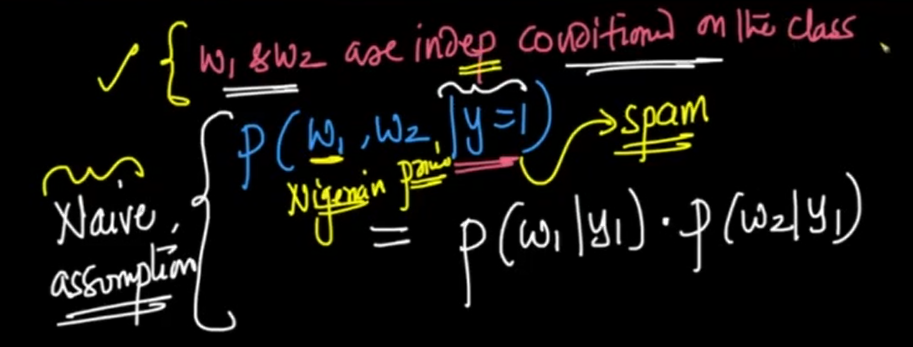

Since now the words are indpendent of each other on the condition that y=1, we can say:

- $P(w_1. w_2, w_3, ..., w_d|y=1) = P(w_1|y=1)*P(w_2|y=1)*...*P(w_d|y=1)$

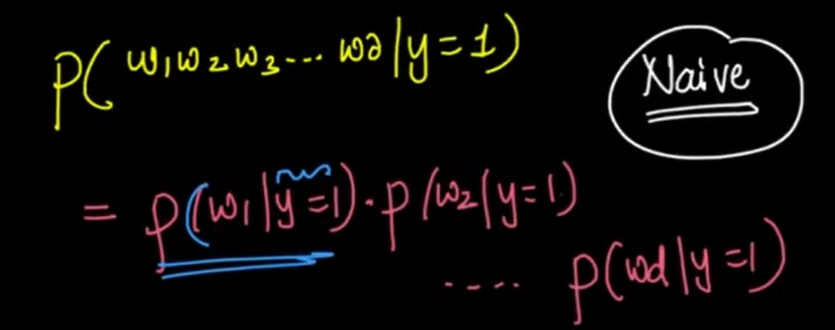

## Q. How can we find $P(w_{1}|y=1)$ ?
Since $P(w_{1}|y=1)$ means the probability of having the word $w_1$ in our text, given that the text is spam (y=1)

- We go through all the texts that are spam (where y=1). Let the total number of texts that are spam in the dataset be n<sub>1</sub>  
- Find the number of texts where the word **w<sub>1</sub> exists**. Let the number of texts where we find this word be $n_{1}'$

So, $P(w_{1}|y=1)$ becomes $P(w_{1}|y=1) = \frac{n_{1}'}{n_{1}} $

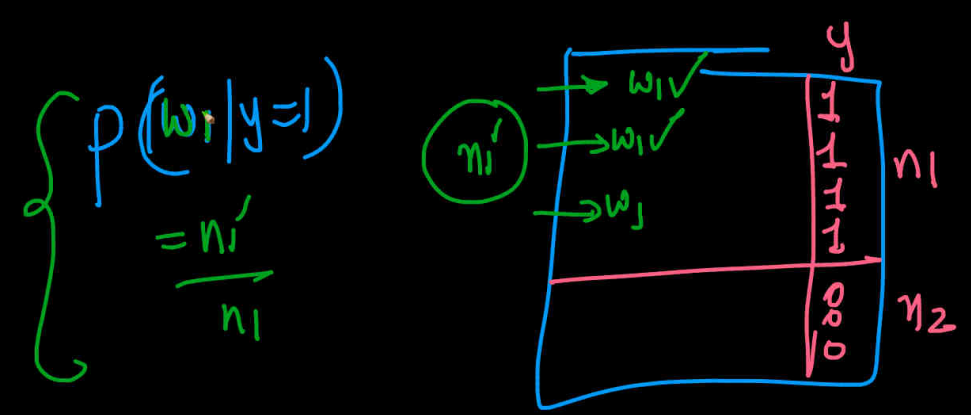

We had already seen how to calculate the terms $P(y=1)$ and $P(y=0)$

We just saw how to calculate the value for $P(w_1, w_2, ..., w_d|y=1)$ and $P(w_1, w_2, ..., w_d|y=0)$ using our **naive assumption**

<br>

So, putting these both together, we can write $P(y=1|text)$  as:-

$P(y=1|text) = \frac{P(y=1) * P(w_1|y=1) * P(w_2|y=1) * P(w_3|y=1) * ... * P(w_d|y=1)}{k}$

<br>

We can simplify this by using the $Π$ notation for multiplication as:

 $P(y=1|text) = \frac{P(y=1) * Π_{i=1}^d P(w_i|y=1)}{k}$

<br>

Similarily, we can get the expression for $P(y=0|text)$ also as:-

$P(y=0|text) = \frac{P(y=0) * Π_{i=1}^d P(w_i|y=0)}{k}$




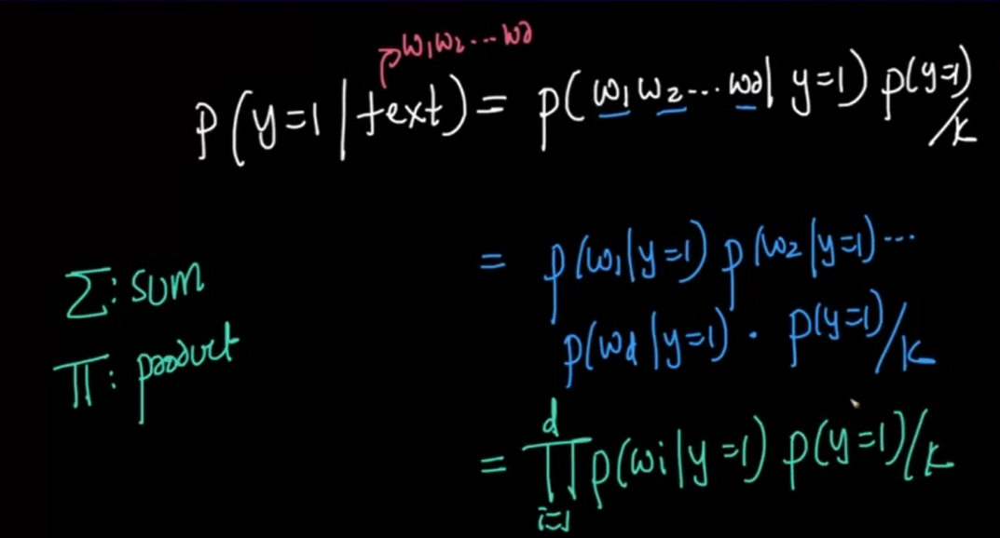

**QUIZ**

```
Naive assumption is 'In a sentence, words are independent of each other':

1. True
2. False

```
**ANSWER**
2. False

**EXPLANATION**

naive assumption is that "the events of occurence of words  𝑤𝑖1,𝑤𝑖2,𝑤𝑖3,...,𝑤𝑖𝑑  is independant of each other,
- but conditioned on the class (i.e. whether y=1 or y=0)".


## Q. How can we make the final prediction of whether a text is spam or not ?

By simply comparing $P(y=1|text)$ and $P(y=0|text)$, and which ever one is higher becomes our final prediction

Recall that we simply cancel out the constant $k = P(𝑤_𝑖^1,𝑤_𝑖^2,𝑤_𝑖^3,...,𝑤_𝑖^𝑑)$ from both the equations, since the constant is same in both $P(y=1|text)$ and $P(y=0|text)$

<br>

**Note:**
- The terms $P(y=1)$ and $P(y=0)$ are called **class priors**.

 - It is simply the probability that a data point belongs to class 0 or 1.

- While The terms $P(w_{i}|y=1)$ and $P(w_{i}|y=0)$ are called **likelihoods**.
 - Likelihood is the probability of occurence of each word, conditioned on the class.

- hence we can write:
 - P(y=1|text) = (class prior)*(product of likelihoods)

<br>

We used a Naive assumption along with Baye's theorm, hence we get the name Naive Bayes for this algorithm!




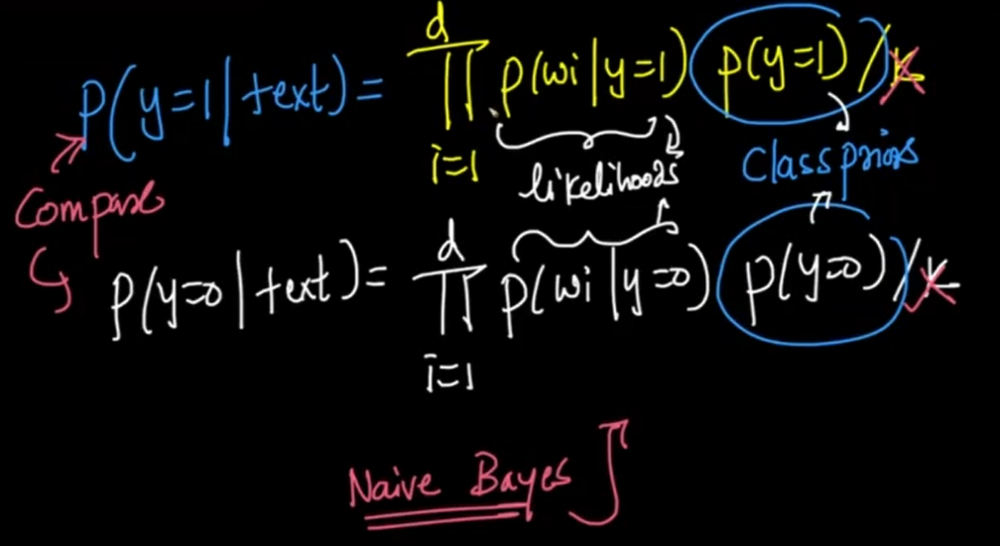

**QUIZ**

```
Which class will the text belong to when P(y=1|text_i) = 0.30 and P(y=0| text_i ) = 0.25

1. Class 1
2. Class 0
```
**ANSWER**
1. Class 1


**QUIZ**
```
Which of the following statement is TRUE about the Bayes classifier?

1. Bayes classifier is an unsupervised learning algorithm.
2. Bayes classifier works on the Bayes theorem of probability.
3. Bayes classifier is a Reinforcement Learning Algorithm
4. It assumes the independence between the independent variables or features.
```



ANSWER
1. Bayes classifier works on the Bayes theorem of probability.



**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/23532/


# **Q. Why Naive Bayes?**
If our task is a simple classification task with natural language text, Naive Bayes is a very popular model. This is so because:-
- **Simple**
 - As opposed to state of the art technology for NLP, **transformers**
 - Transformers are crazy complex
 - Just making sure they are working fine is a big challenge.
- **Super Fast**
- **Works really well for simple NLP tasks**
 - Fetches about 80-90% accuracy, whereas state of the art methods would fetchs about 98.5% or so accuracy.
- **Interpretable**
 - A smart and interpretable model that works really well for simlpe tasks.


**QUIZ**
```
Naive Baye is ___ .


1. Conditionally Independent

2. Conditionally Dependent

3. Both a and b

4. None of the above
```

ANSWER
1. Conditionally Independent

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/16710/



---
---
---

## **Train time of Naive Bayes**

#### Q. We have seen the mathematical intuition of Naive Bayes, but what exactly happens during training and testing?

Lets look into how training of Naive Bayes is done

First lets look on how our training dataset looks like:

<br>

#### Q. What will be features for Naive Bayes model ?
All the **unique words** present in all the texts of our dataset.

These set of all unique words in the dataset becomes Corpus for our data

Now lets assume we have w1,w2,w3.....wd unique words

- All the samples of the dataset becomes our text_i or $x_i$
- And for each sample we have a corresponding $y_i$ label

<br>

#### Q. What do we need to calculate during testing in NB?
Recall that for finding $P(y=1| w1,w2...wd)$ we basically need to find two things:
- Class Priors
    - P(y=1)
    - P(y=0)
- Likelihoods
    - $P(w_{j}|y_{i}=1)$
    - $P(w_{j}|y_{i}=0)$

<br>


#### Q. How will we calculate class priors for train dataset ?
- we first find the number of samples where $y_i=1$ and divide it with the total number of samples  in our training data

 - $P(y=1) = \frac{Number \ of \ samples \ with \ y_i=1}{Total \ number \ of \ samples}$

- Similarly, we find for $P(y=0)$,
 - $P(y=0) = \frac{Number \ of \ samples\ with \ y_i=0}{Total \ number \ of \ samples}$

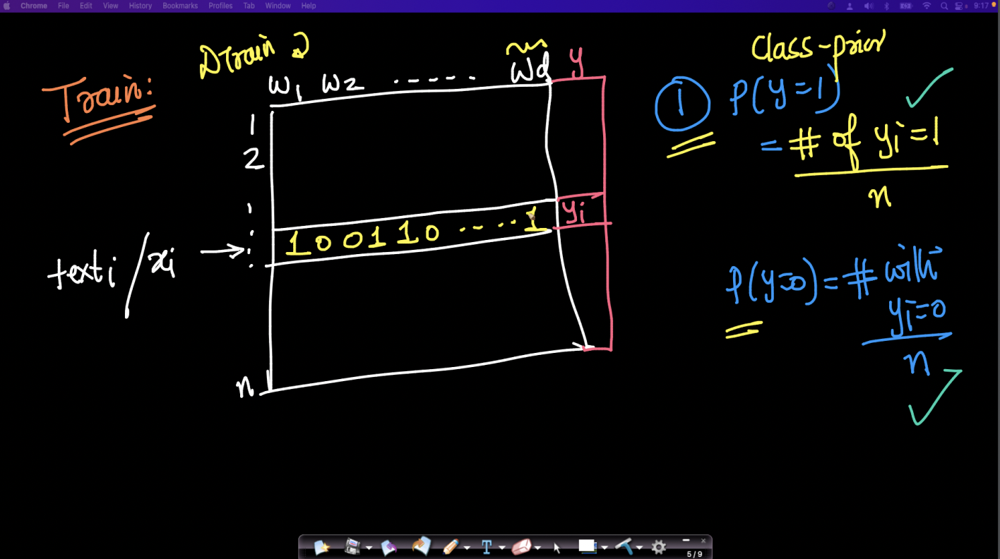

#### Q. How do we calculated the **likelihood** of **all words** (from 1 to d) for **both classes** (y=0 and y=1)?
These values are calculated using the **conditional probability** concept that you must've read about in the **pre-read**.

Lets consider $P(w_{j}|y_{i}=1)$ first,

- Thus, for a particular jth word $w_j$, we compute probabilty for all the datapoints where $y_i = 1$ and $w_j$ exists in that $text_i (x_i)$
- This is calculated as: $P(w_{j}|y_{i}=1) = \frac{P(w_{j} \cap y_{i}=1)}{P(y_{i}=1)} $

Similarily, the probability of occurence of word w<sub>j</sub> in a text with $y_i = 0$ (i.e. not spam) becomes $P(w_{j}|y_{i}=0) = \frac{P(w_{j} \cap y_{i}=0)}{P(y_{i}=0)} $

**NOTE:** Since there are d unique words, we get d such likelihood values for $y_i= 1$ (Spam) , and d different values for $y_i= 0$ (not Spam).

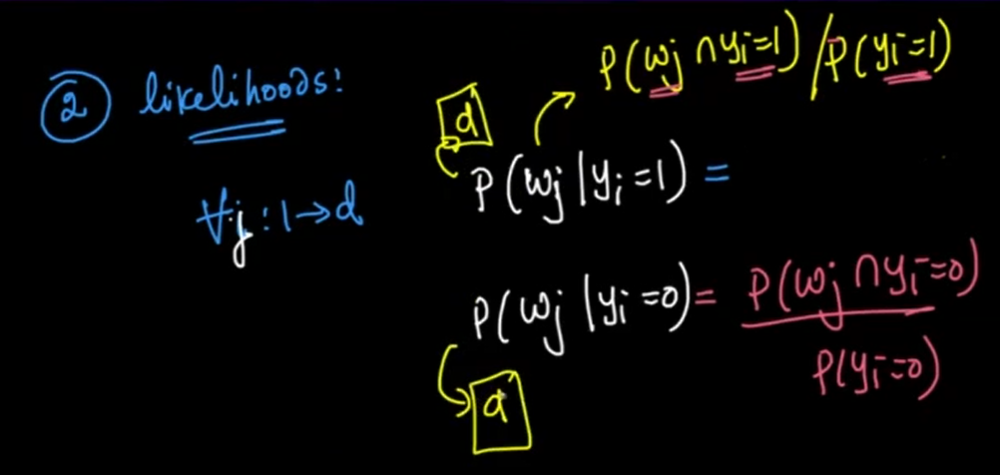

#### Q. How is Naive bayes getting trained here even though we do no weight updates?
We are computing d likelihoods for both classes along with class priors which is **analogous** to computing weights of the model.

#### Summarizing the things we have learnt from training Naive Bayes
- we will have two constants, both the class priors
 -   $P(y=1) = \frac{Number \ of \ samples \ with \ y_i=1}{Total \ number \ of \ samples}$
 -   $P(y=0) = \frac{Number \ of \ samples \ with \ y_i=0}{Total \ number \ of \ samples}$
- And d likelihood values for both classes
 - $P(w_{j}|y_{i}=1) = \frac{P(w_{j} \cap y_{i}=1)}{P(y_{i}=1)} $
 - $P(w_{j}|y_{i}=0) = \frac{P(w_{j} \cap y_{i}=0)}{P(y_{i}=0)} $

### What will be the **Training time complexity** of the Naive Bayes ?
Since we are to compute d likelihoods for all the n samples of the data
- the time complexity becomes **o(nd)**

# Test time of Naive Bayes

#### Q. Now that we have learnt about training dataset of Naive Bayes, what about the test dataset?
Suppose we have a query text  consists of the following words $text_{q} = w_{1}, w_{3}, w_{6}, w_{12}, w_{15}$

Note that, We have already calculated the class priors and the likelihoods of all words, for both classes in the training of our model.

<br>


#### Q. How will we predict $text_{q}$ belongs to $y_q=1 $ or $y_q=0$ ?
First, we need to calculate the probability of $y_q=1$ when words $w_{1}, w_{3}, w_{6}, w_{12}, w_{15}$ exist in the text.
- Recall this will be calculated as:
 - $P(y_q=1|w_{1}, w_{3}, w_{6}, w_{12}, w_{15}) ∝ 𝑃(𝑦=1)∗𝑃(𝑤_1|𝑦_𝑖=1)∗𝑃(𝑤_3|𝑦_𝑖=1)∗𝑃(𝑤_6|𝑦_𝑖=1)∗𝑃(𝑤_{12}|𝑦_𝑖=1)∗𝑃(𝑤_{15}|𝑦_𝑖=1)$

<br>

#### Q. Why are we using Propotionality sign while finding $P(y_q=1|w_{1}, w_{3}, w_{6}, w_{12}, w_{15})$ ?
Recall we defined $P(y=1|text_i)$ as  $\frac{P(y=1) * Π_{i=1}^d P(w_i|y_i=1)}{k}$ where k was $P(w_1,w_2...w_d)$ and how we discarded k from the equation since we are comparing $P(y=1|text_i)$ and $P(y=0|text_i)$ and k, a constant exist in both.

<br>

#### Q. How will we calculate the probability of $text_q$ being a spam or not?
We already have class prior and likelihood values calculated from training.

Notice how we only have 5 words in $text_q$

so the product of likelihoods can be clubbed from j=1 to k where k = 5.
 - $P(y_q=1|w_{1}, w_{3}, w_{6}, w_{12}, w_{15}) ∝ 𝑃(𝑦=1)∗ ∏_{j=1}^{k}  𝑃(𝑤_j|𝑦=1)$

Similarily, we can find the probability of $y_q=0$ when words $w_{1}, w_{3}, w_{6}, w_{12}, w_{15}$ exist in the text.

 - $P(y_q=0|w_{1}, w_{3}, w_{6}, w_{12}, w_{15}) ∝ 𝑃(𝑦=0)∗ ∏_{j=1}^{k}  𝑃(𝑤_j|𝑦=0)$


Now we compare the probability for both the classes and which ever one is higher, Naive bayes predicts that class as the $y_q$ for $x_q$

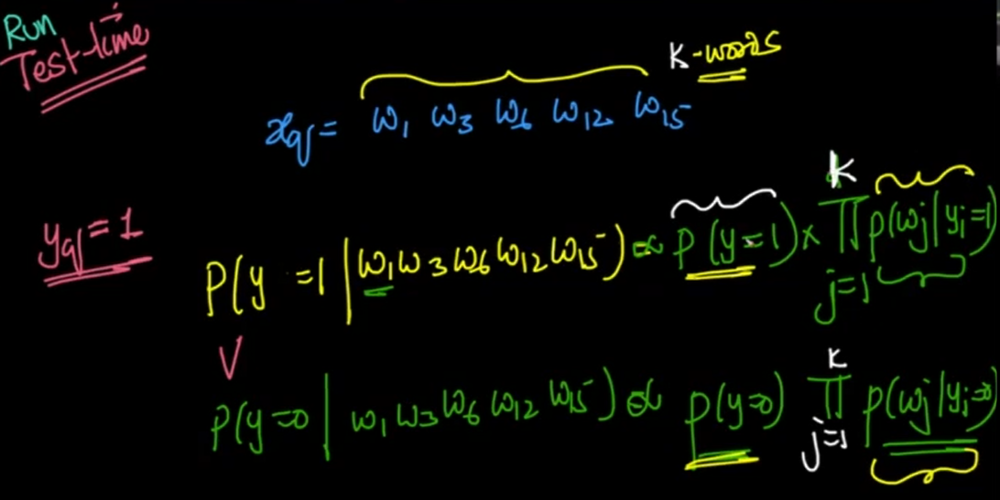

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/16812/



### Complexity of Naive Bayes



#### Q. based on both the training and test dataset of Naive Bayes, what will be the the space complexity at runtime ?
So, if you recall what we've studied, during training, we only need to store the values of **class priors** and the **likelihood** values for both classes.
- For class priors, we only have two values that need to be stored, P(y=0) and P(y=1)
- For likelihood, we get d values for $y_i=0$, and d values for $y_i=1$. Where d is the number of unique words that exist across all texts.
 - This means, we store d + d = 2d values for likelihood

This means, in total we store 2+2d values, so the space complexity becomes
 O(2d+2) = **O(d)**

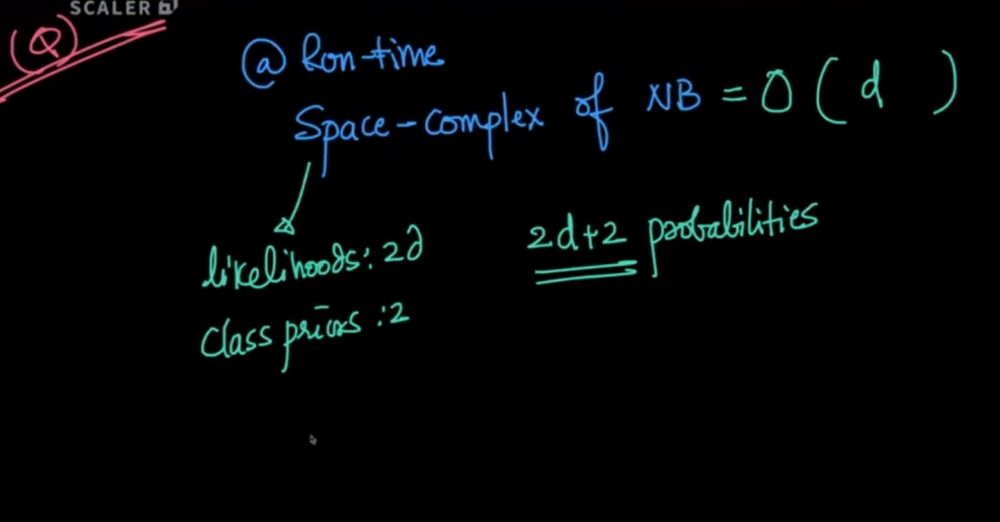

**QUIZ**

```
If the samples = 40 and total words = 50, then what is the train and test time complexity ?

1. O(40*50) and O(40)
2. O(50) and O(40*50)
3. O(40*50) and O(50)
4. O(40) and O(50*40)

```
**ANSWER**
3. O(40*50) and O(50)
**EXPLANATION**

Since n is the number of samples and d is the total number of words
- here n = 40 and d =50
- We know Train complexity = O(nd) = O(40*50)
- While Test complexity = O(d) = O(50)


Now Suppose the $text_q$, contains k words.

####Q. What is the runtime complexity for predicting the class label for $text_q$?
So, in order to compute the $P(y=1|w_{1}, w_{2}, ..., w_{k})$ and $P(y=0|w_{1}, w_{2}, ..., w_{k})$ values, we need the already calculated class prior values and the likelihood values for these k words.
 - Therefore, there will be 2 class prior values.
 - k values for $P(y=1|w_{1}, w_{2}, ..., w_{k})$
 - k values for $P(y=0|w_{1}, w_{2}, ..., w_{k})$

Therefore total values to compute the $P(y=1|w_{1}, w_{2}, ..., w_{k})$ and $P(y=0|w_{1}, w_{2}, ..., w_{k})$ becomes 2k+2,

Meaning our complexity becomes: O(2k+2) = **O(k)**

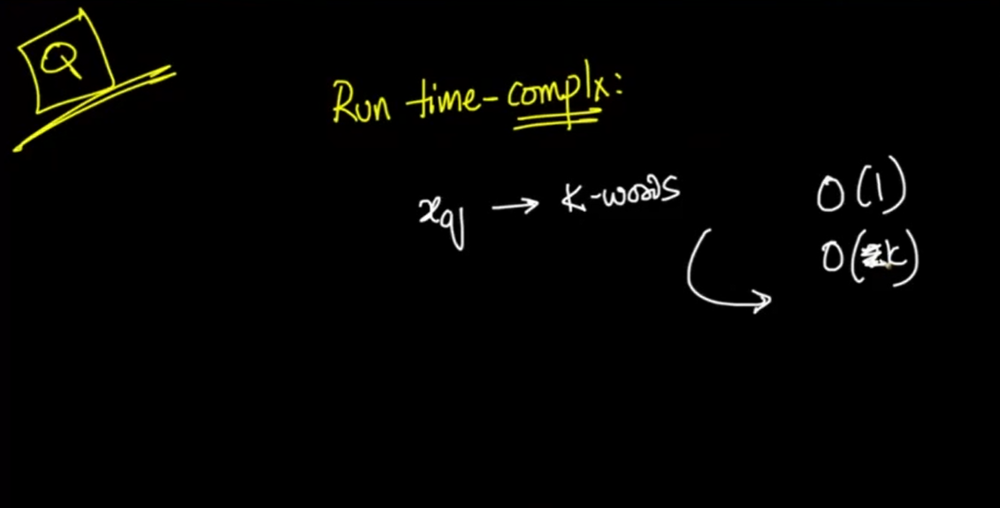

**QUIZ**

```
If we have 50 words in a sentence how many likelihoods will the naive bayes have to store?

1. 25
2. 50
3. 100
4. 52
```
**ANSWER**
3. 100

**EXPLANATION**

50 Likelihoods for class 1 and 50 likelihoods for class 2 hence total = 100



**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/23534/





# **Laplace Smoothing (@25:00 in video)**


Now suppose in our test data, we have a query text x_q which contains words {w1,w2,w6,w7,w'}

#### Q. If w' is a word which does not belong to the set of all unique words in the training dataset , will Naive Bayes be able to predict the y_q correctly ?
No. Naive Bayes fails to predict.

Lets see why, using the same query $text_q$ ($x_q$)

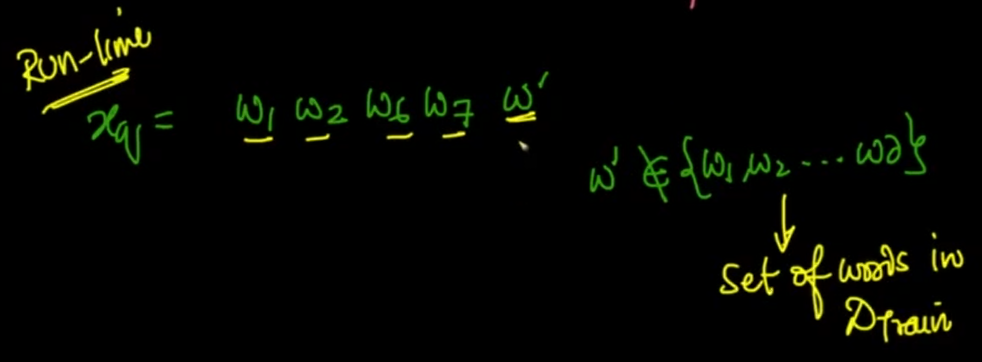

Now in the test time, Naive Bayes computes $P(y=1|w_{1}, w_{2}, w_{6}, w_{7}, w')$   and 𝑃(𝑦=0|𝑤1,𝑤2,𝑤6,𝑤7,𝑤′)


 if we consider $P(y=1|w_{1}, w_{2}, w_{6}, w_{7}, w')$ ,
- $P(y=1|w_{1}, w_{2}, w_{6}, w_{7}, w') = P(y=1)*P(w_{1}|y=1)*P(w_{2}|y=1)..*P(w'|y=1) $

<br>

#### Q. **In this expression, how will we calculate $P(w'|y=1)$?**
As w' has never been in the training dataset, the occurence of word w′ when $y_i = 1$ will be 0 (i.e. $n_{w'_1} = 0$),
- hence $P(w'|y=1) = 0$ which makes $P(y=1|w_{1}, w_{2}, w_{6}, w_{7}, w') = 0 $

Now similarly if we compute $P(y=0|w_{1}, w_{2}, w_{6}, w_{7}, w')$
- since the occurence of word w′ when $y_i = 0$ will be again 0, which makes $P(y=0|w_{1}, w_{2}, w_{6}, w_{7}, w') = 0 $

<br>

#### Q. How can Naive Bayes predict when both  $P(y=1|w_{1}, w_{2}, w_{6}, w_{7}, w')$ =  $P(y=0|w_{1}, w_{2}, w_{6}, w_{7}, w')$ = 0 ?
It simply cannot, hence a hack is required in order for Naive Bayes to work.

<br>

#### **Q. Why not just add all the unique words in English as features in the Training dataset ?**
To add all of these words as features into the training dataset will make time and space complexity of the model very high.



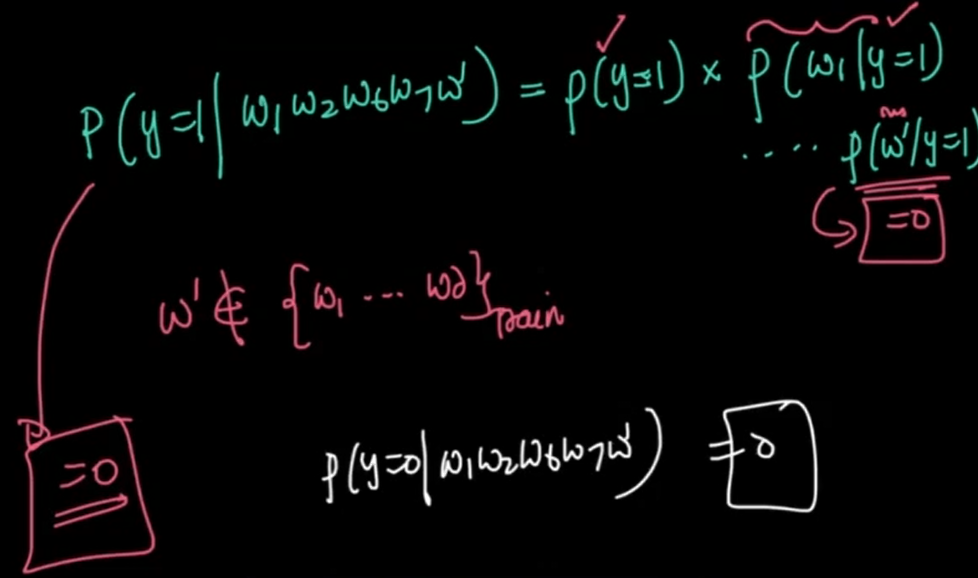

#### Q.**Why $𝑃(𝑤′|𝑦=1)$ and $𝑃(𝑤′|𝑦=0)$ becomes zero?**

If we recall, $𝑃(𝑤_𝑗|𝑦=1)$ is just the number of times word wj occurs in all the samples of the data when $y_i=1 $ ($n_{j1}$) divided by the total number of samples having $y_i = 1$ (n1) i.e. $𝑃(𝑤_𝑗|𝑦=1) = \frac{n_{j1}}{n_{1}}$

Therefore, $P(𝑤'|𝑦=1)$, is just the number of times word w' occurs in all the samples of the data when $y_i=1$ ($n_{w'_1}$) divided by the total number of samples having $y_i = 1 $(n1)

So, when we try to calculate this for a new word $w'$, we get $n_{w'_1} = 0$, as it never occured before in the training data, giving us $P(𝑤'|𝑦=1) = 0$.
 - $𝑃(𝑤'|𝑦=1) = \frac{n'_{1}}{n_{1}} = \frac{0}{n_1} = 0$




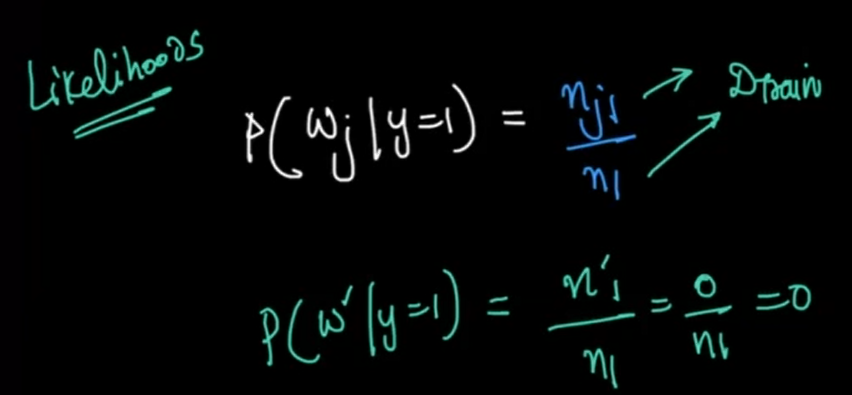

## **Q. How can we prevent $P(𝑤'|𝑦=1)$ and $P(𝑤'|𝑦=0)$ from becoming equal to 0?**
- What if we ignore the term $P(𝑤'|𝑦=1)$ and $P(𝑤'|𝑦=0)$ for the new word w' ?
 - We can do this, if we just assign the value of $P(w'|y=1)$ and $P(w'|y=0)$ as 1.
 - This way, as this becomes 1, we can say that it's value did not bother the main product.
 - Though this approach can work fine, we look at another approach as it works better.

- As $n_{w'_1}$ is becoming equal to 0, what if we add some constant to the $n_{w'_1}$ and n1 part of 𝑃(𝑤′|𝑦=1) ?
 - Now suppose for $n_{w'_1}$ we add a constant 𝛼 <br> while for n1 we add a constant C𝛼
 - This way, we will not get 0 as result.
 - This technique is called as **Laplace smoothing** or **Additive Smoothing**.



**Quiz**

```
In a naive Bayes algorithm, when an attribute value in the testing record has no example in the training set, then the entire posterior
probability will be zero.

1. True
2. False
```
Answer
1. True



**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/25984/

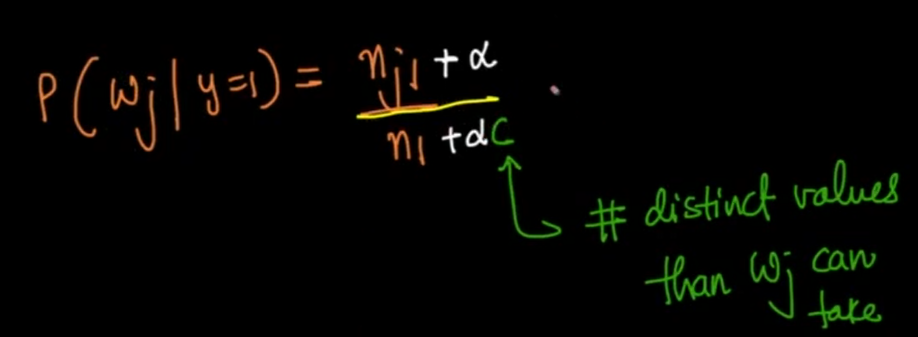

#### **Q. How does addition of constants, prevent P(𝑤'|𝑦=1) and P(𝑤'|𝑦=0) from becoming equal to 0?**
For this lets consider an example

Assuming there are 100 texts in training data which has y = 1, Lets take value of 𝛼 = 1 and C = 2

Suppose we encounter a new word w' that does not belong in the training dataset.

Lets apply Laplace Smoothing on it's likelihood term.
   - $P(w'|y=1) =\frac{0+1}{100+(1*2)} = \frac{1}{102} = 0.0098$
   - Notice how the p(𝑤'|𝑦=1) is a very small value, hence laplace smoothing does not break the math behind Naive Bayes model

<br>

To recap:
- This **does not break the math** we worked out for Naive Bayes
- **Solves** the multiplication with 0 problem
- Probability we get is **very small**.
- This is a mathematical hack that makes things work.

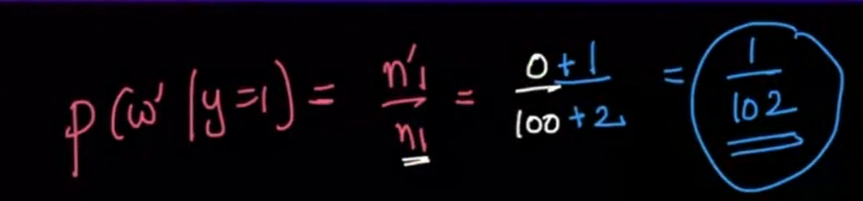

## **Q. Will laplace smoothing constants be added only on the new words?**
No.
Whenever we perform Naive Bayes with Laplace smoothing.

We don't do Laplace smoothing for just the new words that are missing from the training set.

We tend to do the smoothing in the likelihoods for **all the words** present in both training and testing data

$P(w_{j}|y=1) = \frac{n_{j1}+\alpha}{n_{1}+2\alpha}$ where C=2
  


#### **Q. Why do we take the value of C=2?**
- Recall that we defined C as the "Number of distinct values that the word wj can take".
 - w<sub>j</sub> is a Bernoulli random variable.
 - There are **two** possibilities, either the word exists or it doesn't exist (i.e. either the value of $w'$ would be **0 or 1**).
 - Hence we take value of **C=2**

Imagine a case where in our training data, we have **no data belonging to class 1 (n1=0)**
 - In reality, this should never happen, but lets explore the possibility for theoretical purposes.

This means that $n_{1}=0$ and thereby by extension, $n_{j1}=0$ also
 - This Implies, $P(w_{j}|y=1)=\frac{0+\alpha}{0+\alpha C} = \frac{1}{2}$ (consider C=2)

This means that the probability that we observe word w<sub>j</sub> given the class label is 1: $P(w_{j}|y=1)= 0.5 $

This makes logical sense, because we have not seen **any words occuring in class 1** as of yet, and we have not seen **any occurence of the word w<sub>j</sub>**.

So naturally this probability should be 0.5, because both, the presence or the absence of this word in class 1 is **equally probable** since we have **no data**.

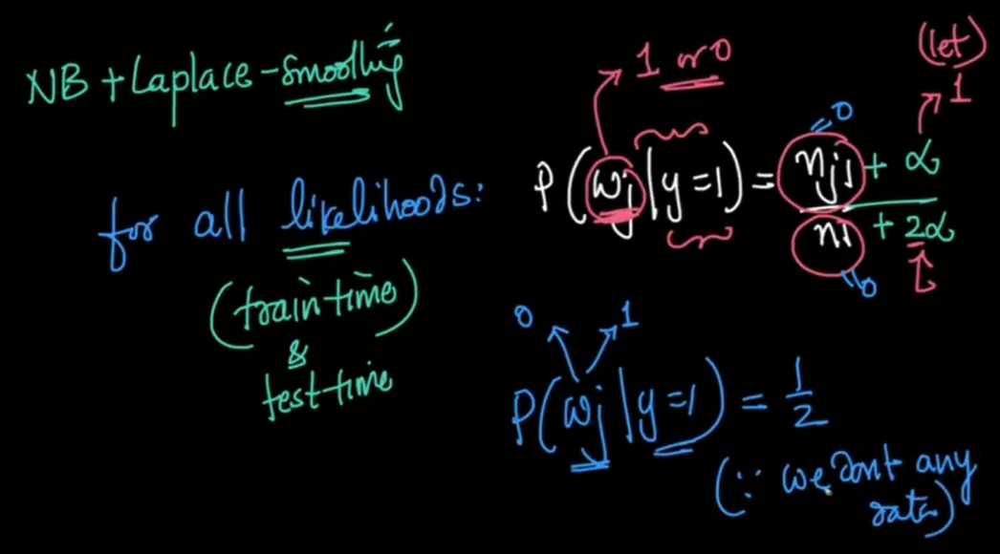

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/16813/

- https://www.scaler.com/hire/test/problem/23466/

- https://www.scaler.com/hire/test/problem/23538/

**CODING QUESTION**
- https://www.scaler.com/hire/test/problem/25989/

# **Hyper parameter tuning**

## **Q. What if we took a very large value of constant α in training dataset?** [Timestamp @37:42]

Let's take an example to understand this:

Consider that the training dataset has 100 samples which have $y_i = 1 $ (i.e. $n_1 = 100$)

And we are computing the likelihood for a $text_i$ which has a word $w_j$ such that the number of times that word $w_j$ has occured in the dataset is 10 when $y_i = 1$. (i.e. $n_{j1} = 10$)


Now, if we calculate the likelihood $P(w_j|y=1)$ without any laplace Smoothing,
- $P(w_j|y=1) = \frac{n_{j1}}{n_1} = \frac{10}{100} = 0.1$

<br>

Lets consider the case where we take a small value of α, such as α = 1,
- Then, $P(w_j|y=1) = \frac{n_{j1} + \alpha}{n_1 + 2\alpha} = \frac{10+1}{100+2} = \frac{11}{102} \approx 0.1$  <br>
- Notice that this value is **approximately the same** as when we do not perform Laplace smoothing.

<br>

Now if we took a very large $\alpha$, such that α = 10000, and C = 2

- Then likelihood becomes:
 - $P(w_j|y=1) = \frac{n_{j1} + \alpha}{n_1 + 2\alpha} = \frac{10+10000}{100+20000} \approx  \frac{1}{2}$ <br>

- Notice how by increasing the α value to 10000, the likelihood with and without laplace smoothing differed significantly


<br>

####Q. Why does there is so much difference in the $P(w_j|y=1)$ when we use laplace Smoothing with α = 10000 ?
Since $n_1 = 100$ is very small in comparison to the value of α=10000 ($\alpha >> n_1$), this causes α to **dominate** the probability

Hence we can say, as the value of $\alpha$ increases, **all the likelihoods will tend to be close to 0.5**

Now if we consider $P(y=1|w_1, w_2, ..., w_d)$ and $P(y=0|w_1, w_2, ..., w_d)$, we know it depends on class priors and likelihoods

<br>

#### Q. What will happen to the product of likelihoods of all words  $∏_{j=1}^{j=d} P(w_j|y=1)$ and $∏_{j=1}^{j=d} P(w_j|y=0)$ ?
They will all be close to 0.5 for both $P(y=1|w_1, w_2, ..., w_d)$ and $P(y=0|w_1, w_2, ..., w_d)$, they will simply get cancelled when comparing the two.

Thus making $P(y=1|w_1, w_2, ..., w_d)$ and $P(y=0|w_1, w_2, ..., w_d)$ dependant only on **class prior values**



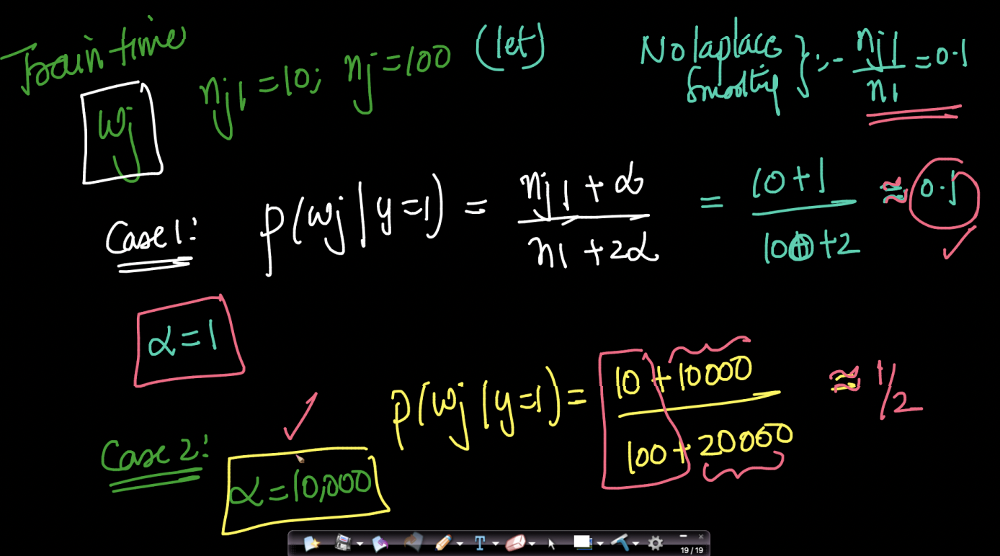


Lets assume that in our training dataset, the texts which have y=1 are more in number as compared to y=0 ,
- Say, $P(y=1)=0.7$ and $P(y=0)=0.3$

#### Q. What will happen to $P(y=1|w_1, w_2, ..., w_d)$ and $P(y=0|w_1, w_2, ..., w_d)$ ?

Since both depends only on the class priors, so on comparing $P(y=1|w_1, w_2, ..., w_d)$ and $P(y=0|w_1, w_2, ..., w_d)$,
 - $P(y=1|w_1, w_2, ..., w_d)\approx 0.7$
 - and $P(y=0|w_1, w_2, ..., w_d \approx 0.3$,


As a result, the Naive Bayes would just return **y = 1** (i.e. spam) for all texts.

<br>

To summarize, We can say that if  𝛼  value is too **large**, it begins **underfitting** the data.

**Note:** If we notice closely, this alpha is analogous the different values of K in KNN. Hence making the alpha as a hyperparameter



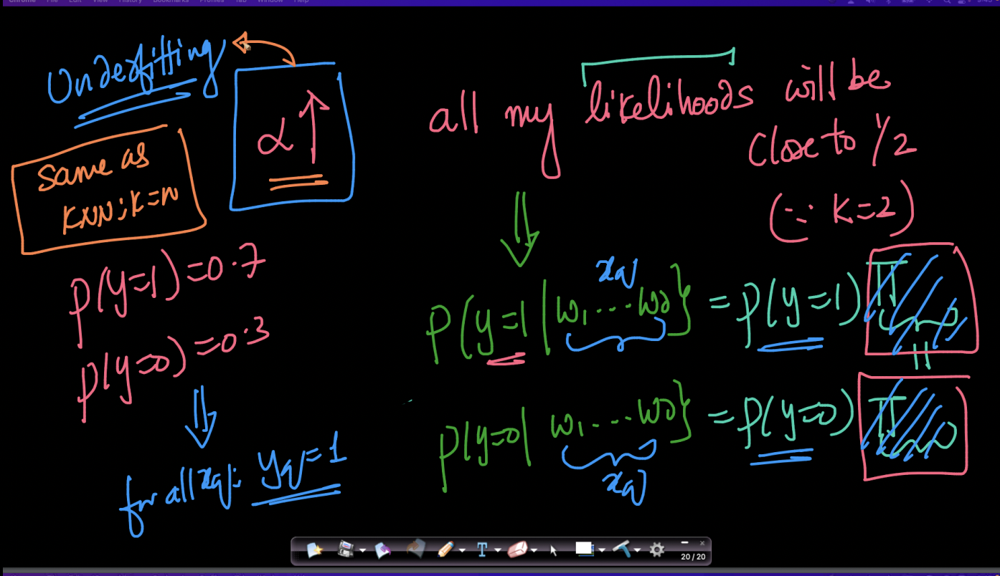

## **Q. What if we took a very large value of constant α  in test time ?** [Timestamp @37:42]
To answer this question, let's take an example

Consider the situation that we are **testing** the $text_q$,  and the dataset has 100 samples where $y_i = 1 $ (i.e. $n_1 = 100$)

Now  suppose we come across a word $w'$ that has never occured in training dataset $(n'_1 = 0)$

Recall that when we took small value of $α$, say 1.

Then, $P(w'|y=1) = \frac{n'_1 + \alpha}{n_1 + 2\alpha} = \frac{0+1}{100+2} = \frac{1}{102}$ <br>

Since $P(w'|y=1)$ was a very small value, it did not break the mathematics behind naive Bayes model

<br>

#### Q. Now if we increased the value of α, such that α = 10000, Will it break the mathematics behind naive Bayes model ?

Since $n_1 = 100$ is very small in comparison to the value of α=10000 ($\alpha >> n_1$), it will make α **dominate** the probability,
- $P(w'|y=1) = \frac{n'_1 + \alpha}{n_1 + 2\alpha} = \frac{0+10000}{100+20000} \approx  \frac{1}{2}$ <br>

- Making $P(w'|y=1)$ **very close to 0.5**.


<br>

#### Recap:
Using all the study of training and test time, we can say

- During test time,
 - irrespective of the α value ,
 - we got rid of the multiplication by 0.

- But during our training time,
 -  As α increases, the likelihoods will become close to 0.5
 - Which will cause $P(y=0|w_1, w_2, ..., w_d)$ and $P(y=1 |w_1, w_2, ..., w_d)$ depend only on class priors. That might cause issue if number of samples of one class is more than the other.



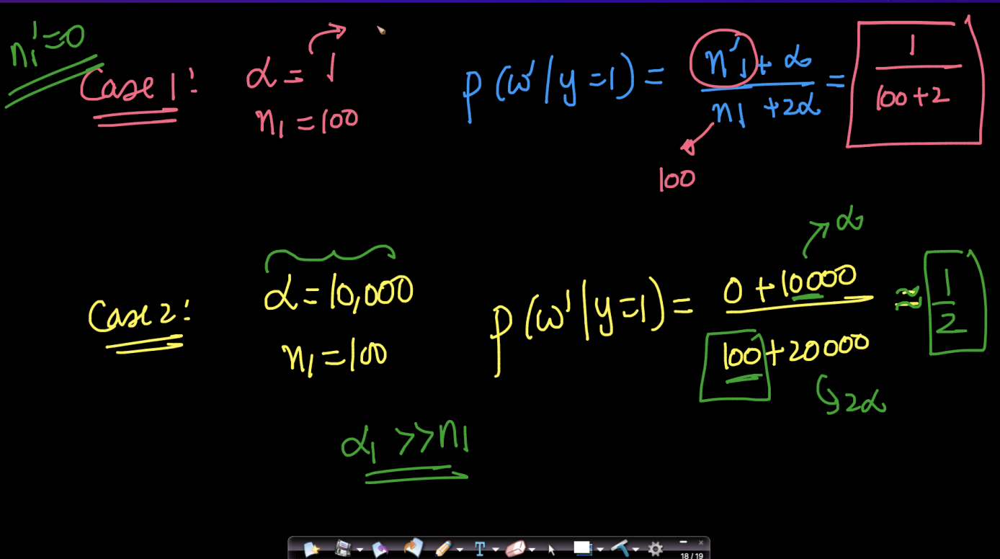

#### Q. What if we decrease the value of laplace smoothing constant α to much small values ?
This will cause the Naive Bayes model to **overfit** the data, because the likelihood with the added constants of Laplace smoothing become closer to the likelihood without  Laplace Smoothing.

Thus making,
 - $ P(w_j|y=1) = \frac{n_{j1}+α}{n_1+αC}≈ \frac{n_{j1}}{n_1}$
 - $ P(w_j|y=0) = \frac{n_{j0}+α}{n_0+αC}≈ \frac{n_{j0}}{n_0}$

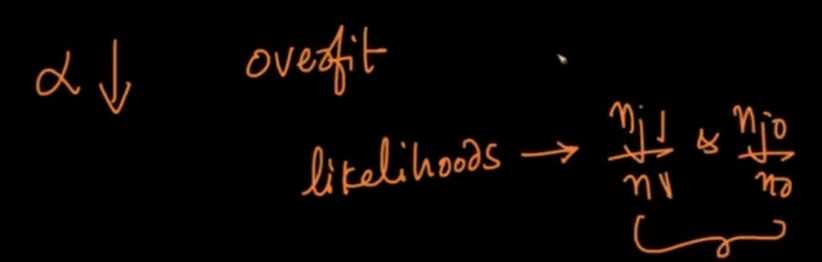

Hence, to summarize, we have a **hyper parameter (α)** using which we can **control the extent of overfitting or underfitting.**

- As **alpha increases**, we begin **underfitting** the data
- As **alpha decreases**, we begin **overfitting** the data



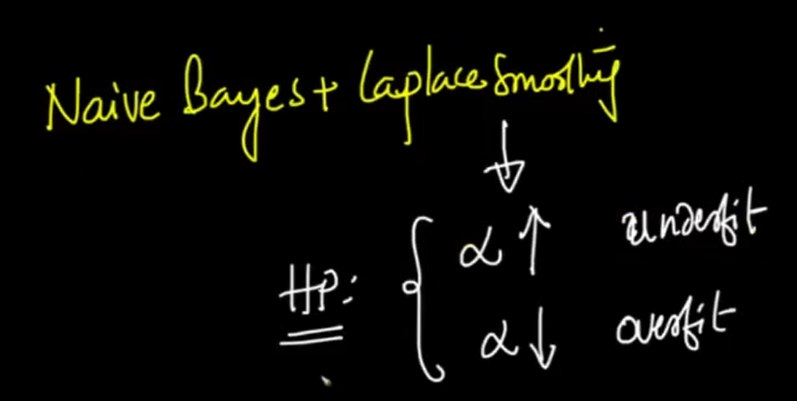


Recall, we talked about how by considering $P(𝑤'|𝑦=1) = 1$ and $P(𝑤'|𝑦=0) = 1 $ we were ignoring the effect of w' on the likelihood.

#### But can we see now , how by just considering $P(𝑤'|𝑦=1) = 1$ and $P(𝑤'|𝑦=0) = 1 $ it causes an issue ?[Timestamp @46:00]

- This causes a lack of any hyperparameter value to be used for Naive Bayes
- which means we would not be able to control the bias-variance tradeoff.

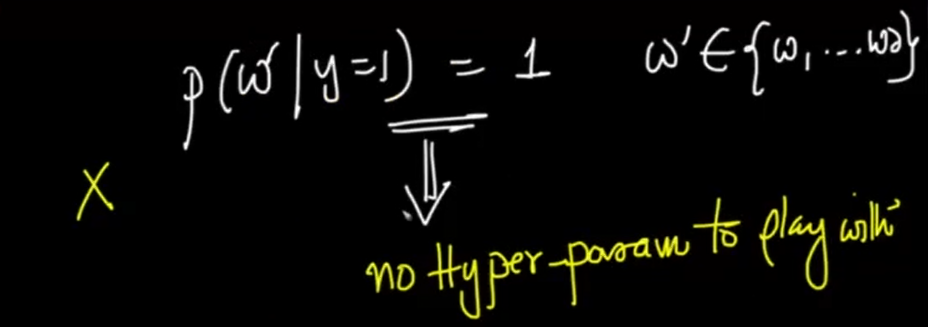

**Assessments Covered**
- https://www.scaler.com/hire/test/problem/23576/

# Impact of imbalance [Timestamp @47:00]

if we noticed closely, when we talked about $𝑃(𝑦=1)=0.7$ and $𝑃(𝑦=0)=0.3$ we are saying our data is imbalanced.


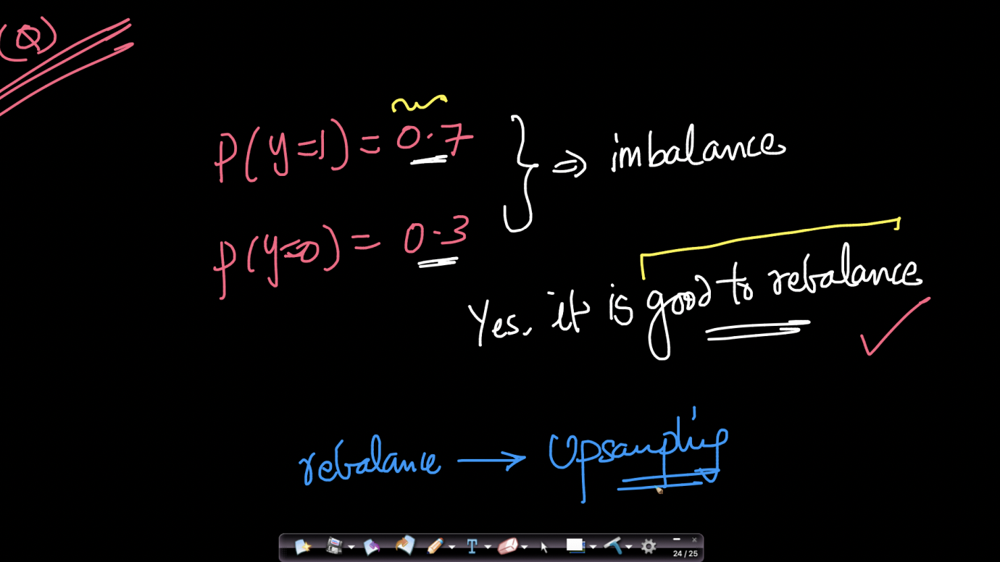

#### Q. Will imbalance in data impact Naive Bayes ?

Lets take an example

Assuming we have the following conditions:-
- $𝑃(𝑦=1)=0.7$,
- $𝑃(𝑦=0)=0.3$
- likelihood for y=1  $∏_{j=1}^{d} P(w_j|y=1)$ is 0.1
- likelihood for y=0  $∏_{j=1}^{d} P(w_j|y=0)$  is 0.2

Now when we compare Probability of Y=1 and Y =0 given a $text_i$ containing {$w_1,w_2...w_d$},  

 - Even though likelihood for y=1 is less, the class prior (P(y=1)=0.7) impacts the overall prediction.

 - $𝑃(𝑦=1|𝑡𝑒𝑥𝑡)=0.7∗0.1=0.07$ comes out to be greater than

 - $𝑃(𝑦=0|𝑡𝑒𝑥𝑡)=0.3∗0.2=0.06$

Thus the class prior for imbalance data is messing up with the prediction for Naive Bayes

Hence **sampling of data** is important.

<br>

#### Q. How does rebalancing of imbalance data help ?
If we notice the issue for 𝑃(𝑦=1|𝑡𝑒𝑥𝑡) > 𝑃(𝑦=0|𝑡𝑒𝑥𝑡) was because of P(y=1) > P(y=0).

Rebalancing makes the class prior values for both y=1 and y = 0 same

- P(y=1) = P(y=0) = 0.5

Now on comparing the P(y=1|text) and P(y=0|text), the Likelihood dominates for prediction by Niave Bayes


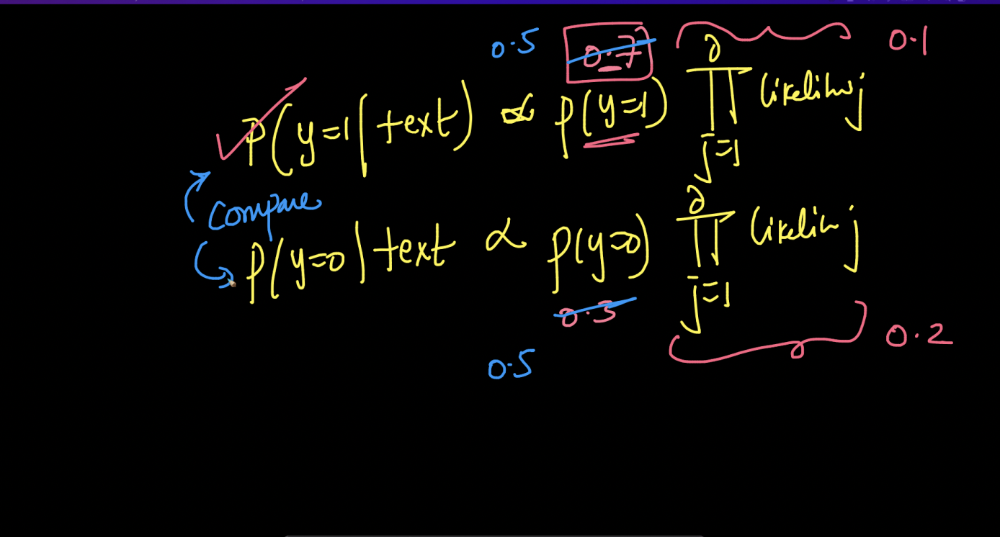

#### **Q. Will sampling the imbalanced data cause likelihoods to change?**
**No**. It does not effect the likelihoods.

<br>

Lets take an example to understand this

Supposedly, we have 1000 samples which had $y=1$ and 500 samples which had $y=0$ (i.e. $n_1=1000$ and $n_0=500$)

Now before rebalancing, if we find the likelihood for $w_j$ when y=0  
- Assuming the number of occurences of $w_j$ when $y=0$ be 50 (i.e. $n_{j0} = 50$).

Therefore the likelihood, which is defined as $P(w_j|y=0) = \frac{n_{j0}+α}{n_0+2α}$, becomes:
  - $P(w_j|y=0) = \frac{n_{j0}+α}{n_0+2α} = \frac{50+α}{500+2α}$
  - which is approx 10% when α small value

<br>

Now after rebalancing, we have just duplicated the samples of $y=0$ such that the number of samples of $y=0$ is now 1000.
 - Thus making $n_{j0}= 50 + 50 = 100$ and $n_0 = 500 + 500 = 1000$

Therefore now the likelihood becomes:
  - $P(w_j|y=0) = \frac{n_{j0}+α}{n_0+2α} = \frac{100+α}{1000+2α}$
  - which is still approx 10% when α small value


Hence the likelihood remians unchanged when balancing the imbalance data




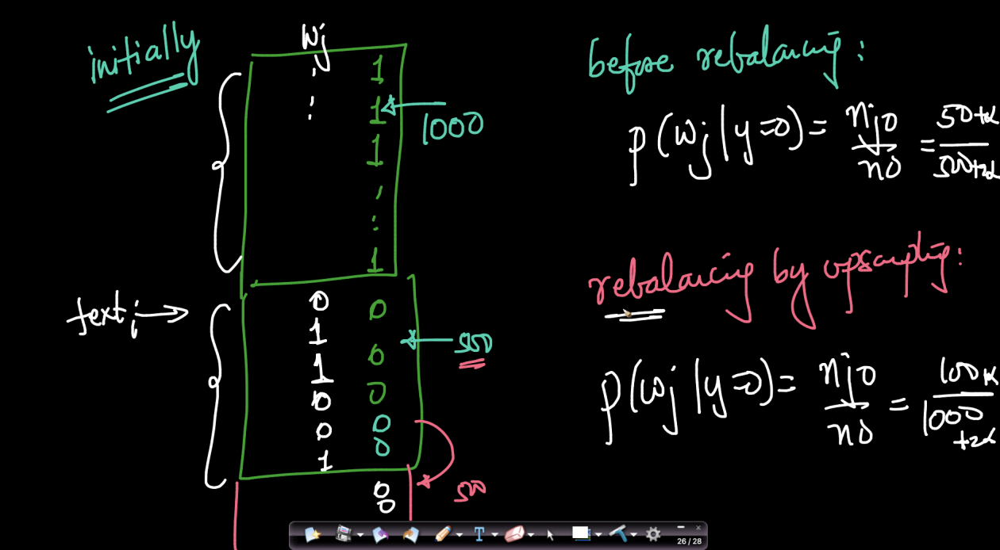

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/16814/

# **Underflow problem** [Timestamp @57:00]


We have seen how Probability of y =1 given $text_i$ containing d unique words  {$w_1,w_2....w_d$} is propotional to the class prior P(y=1) and the likelihood $∏_{j=1}^{d} P(w_j|y=1)$.

Now these d+1 values, 1 being for the class prior value and d values being for the likelihood will have values between 0 and 1

## **Q. What computation problem can the multiplication of these d+1 values cause?**

When multiplying all of the d+1 values which have range 0 to 1, the resultant value can become a very small.

Lets understand this computational problem with an example

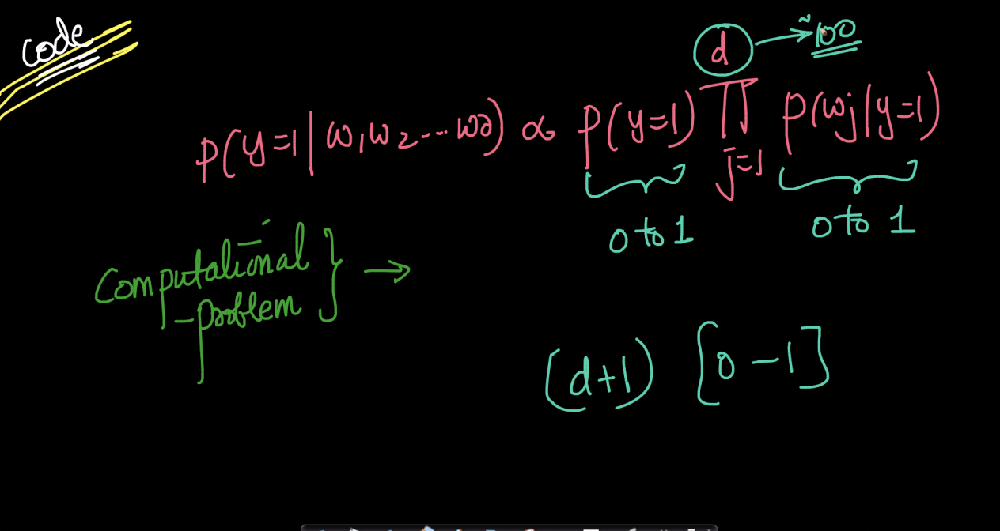

Suppose our text i is $w_1, w_2, w_3$

Let the class prior be  $P(y=1) = 0.1$ ,

And for finding the likelihood, suppose we have:  $P(w_1|y=1) = 0.01$, $P(w_2|y=1) = 0.02$, $P(w_3|y=1) = 0.3$  

Now on multiplying all the d+1 values, the resultant value becomes 0.000123

<br>

Thus as our d increases, the resultant value becomes smaller and smaller

And for our computer only store  a fix bit of value like Float64,

Thus causing the resultant value to no longer be stored in the memory

<br>

**NOTE:** Now this issue of the resultant value becoming too small is what is called Underflow Problem.



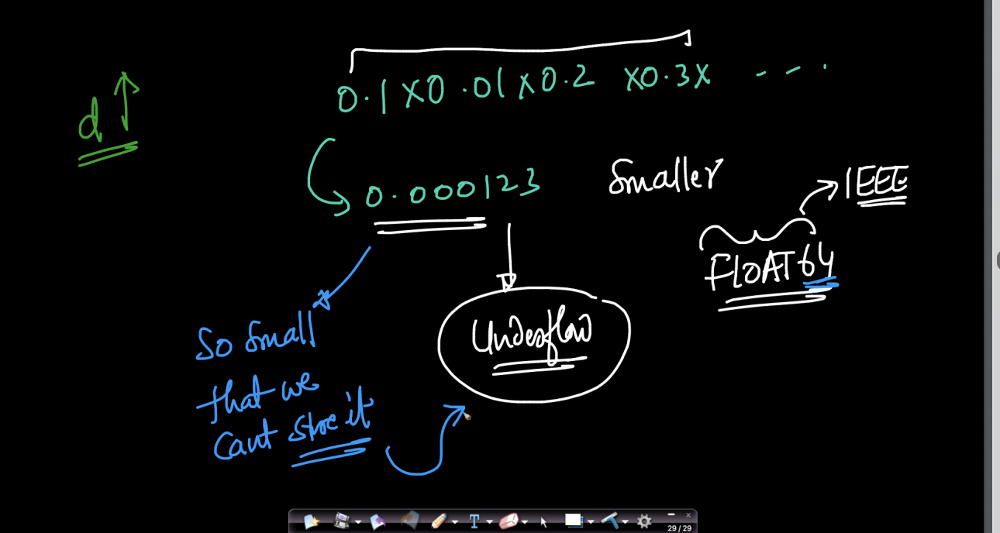

# **Q. Now how can we solve the underflow problem ?**


##### 1. What If we Reduced d ?
 - This wont be an ideal approach since we will be missing out on features/ words which might be useful
 - Leads to information loss

##### 2. What If we use Log ?
Lets see how Logarithm can work

Recall on how we defined the Probability of y=1 given words {$w_1,w_2,....w_d$}:
 - $p(y=1|w_1,w_2..2_d) = P(y=1) ∏_{j=1}^{d} P(w_j|y=1) $

Taking log on both sides
- $log ( p(y=1|w_1,w_2..2_d) ) = log [ P(y=1) ∏_{j=1}^{d} P(w_j|y=1)] $

- Since we know, log(ab) = log a + log b, which means products becomes summation in log

Hence Equation becomes:
 - $log ( p(y=1|w_1,w_2..2_d) ) = log [ P(y=1)] + ∑_{j=1}^{d} log[ P(w_j|y=1)] $


**Note:** addition is more computationally cheaper than multiplication.



#### Q. If we recall log can be negative, isn't that a problem?

**No**.

log is a monotonic funtion, meaning that as x increases , log(x) increases.


Thus if $P(y=1|w_1,w_2..w_d)$ > $P(y=0|w_1,w_2..w_d)$, then log of $P(y=1|w_1,w_2..w_d)$ will be greater than the log of $P(y=0|w_1,w_2..w_d)$ irrespective of the value being +ve or -ve.


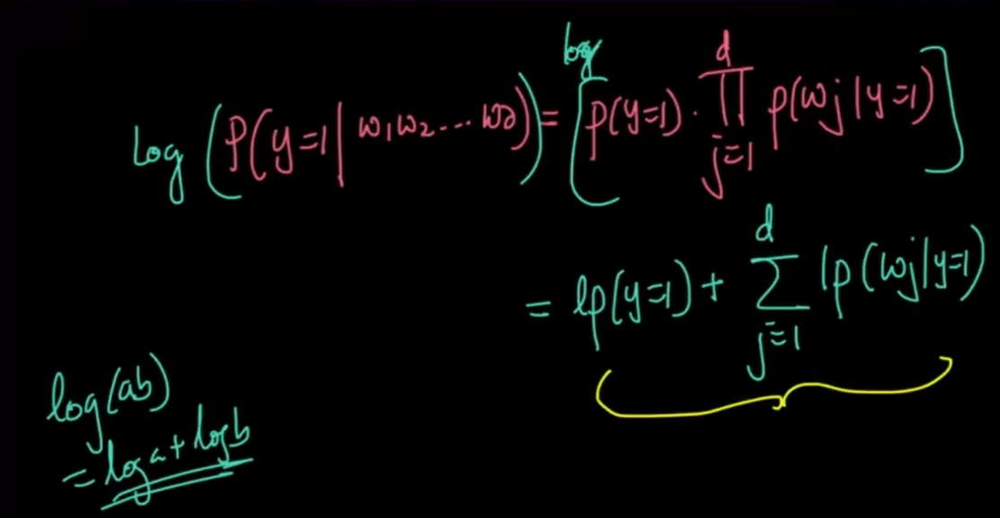

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/23527/

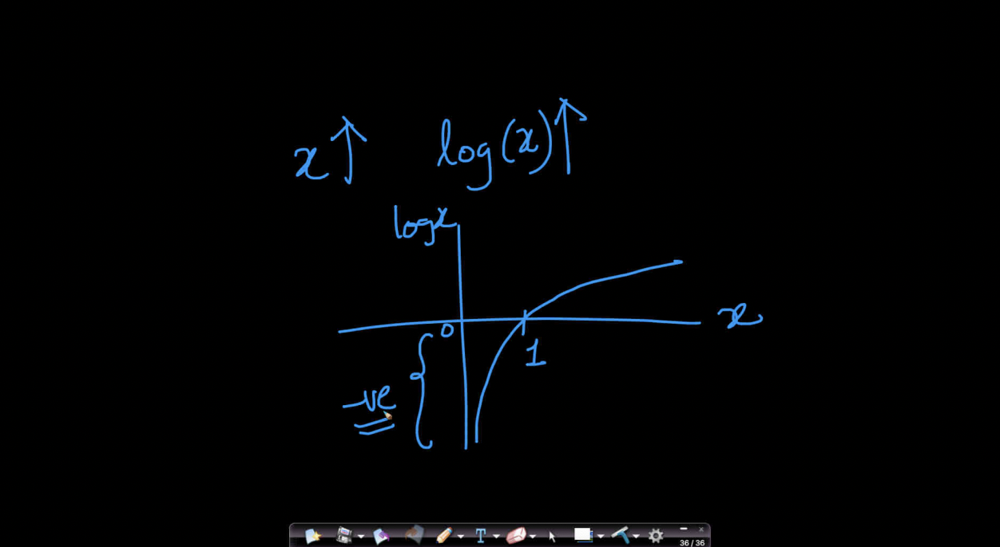

#### Q. Why Naive bayes is Naive ?

Most people say that the words are independent of each other in a text. i.e. $w_i$ and $w_j$ are independent of one another.

This is not true.

Example: If the words "Nigerian" and "Prince" exist together, then we know there is a higher chance the message is spam.

The Naivity of Naive Bayes is assuming that the words $w_i$ and $w_j$ are independent of each other only on the condition when y=1 or y=0.
 - $P(w_i,w_j|y=1) = P(w_i|y=1) * P(w_j|y=1) $


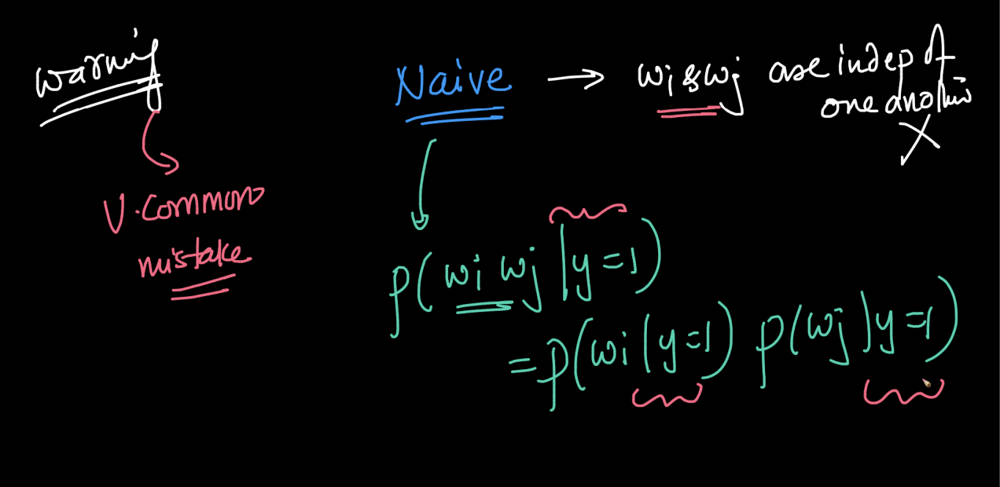

# **Feature Importance and Interpretability** [Timestamp @1:10:000]

Now lets understand the feature importance and interpretability for the Naive Bayes Model

#### Q. What all do Naive Bayes Model have as weights ?

Class prior and Likelihoods

Now supposedly we have a query point $x_q$ and we classified as class 1 ($ŷ_q = 1$).

Since Class Prior remains same when comparing the $P(ŷ_q =1 | x_q ) $ and $P(ŷ_q =0 | x_q ) $  so we have to look into the likelihood part.


Now if We classified $x_q$ to class 1 , this means, We will only focus on the likelihood [$P(w_j|y=1)$] value for ŷ_q = 1


 We can then pick the **top likelihoods** of each word $(w_j)$ from all the d words,

<br>

#### Q. Why only focus on the top likelihood values of each word ?

Because these values are the ones that are actually impacting the likelihood the most.

Hence we can say from the top likelihoods, that these features or words are the most important among the remaining words to find the prediction.


therefore our likelihoods become the feature Importance and Interpretability for Naive Bayes


Lets take an example to understand this more

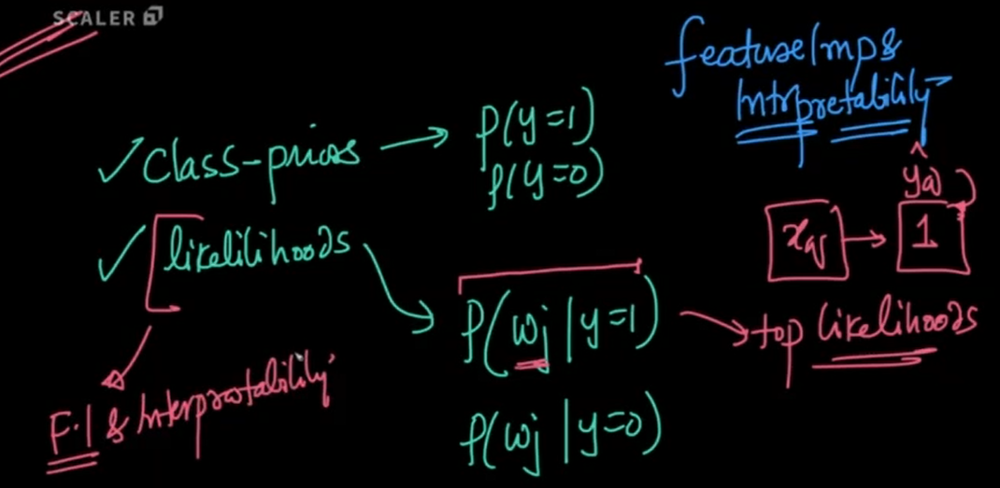

## **Suppose a query point ($x_q$) contains words {$w_1,w_3,w_6,w_7$} and we classifed it as class 1 ($ŷ_q =1$) such that the likelihood for each word is:**
 - $P(w_1|y=1) = 0.01$, $P(w_3|y=1) = 0.01$, $P(w_6|y=1) = 0.8$ , $P(w_7|y=1) = 0.2$

Then from the top likelihood,  we can say that the word $w_6$ and $w_7$ are the ones that effect the decision, with $w_6$ being the most important feature



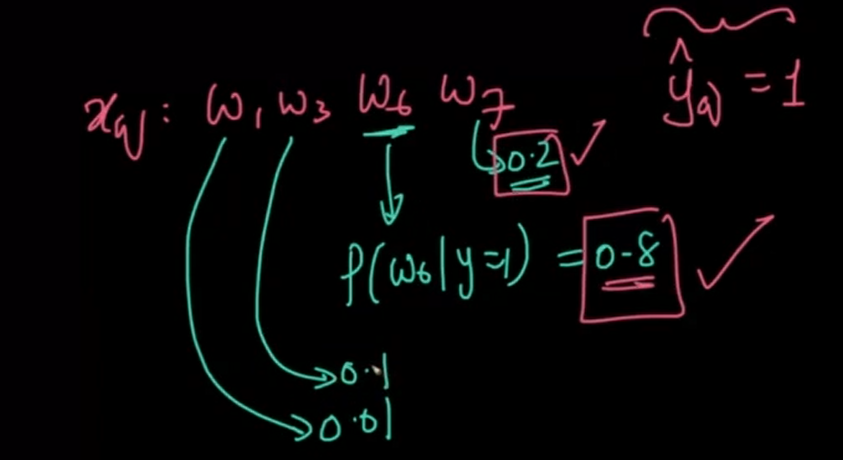

# **Impact of outliers** [Timestamp @1:13:15]

Now lets talk about the outliers on Naive Bayes.

#### **Q. What can be outliers for Naive Bayes in test time ?**

Recall when we discussed about the new word (w') being in test data and not in training data, this word w' becomes our outlier

And we have already seen how **Laplace smoothing** takes care for such outlier.

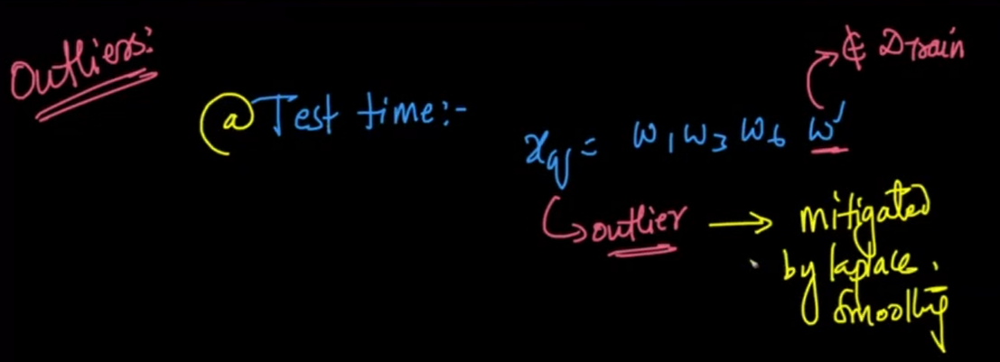

#### **Q. What can be outliers for Naive Bayes in train time ?**

Imagine we have a word $w_j$ which occurs only once, in 1000 samples of training data when y = 1

Thus the number of occurence of word $w_j$ when y =1 becomes: $n_{j1} = 1$

While the number of samples where y = 1 becomes: $n_1 = 1000$

So when computing the likelihood for the word $w_j$, we get:
  $P(w_j|y=1) = \frac{n_{j1}}{n_1} = \frac{1}{1000} $



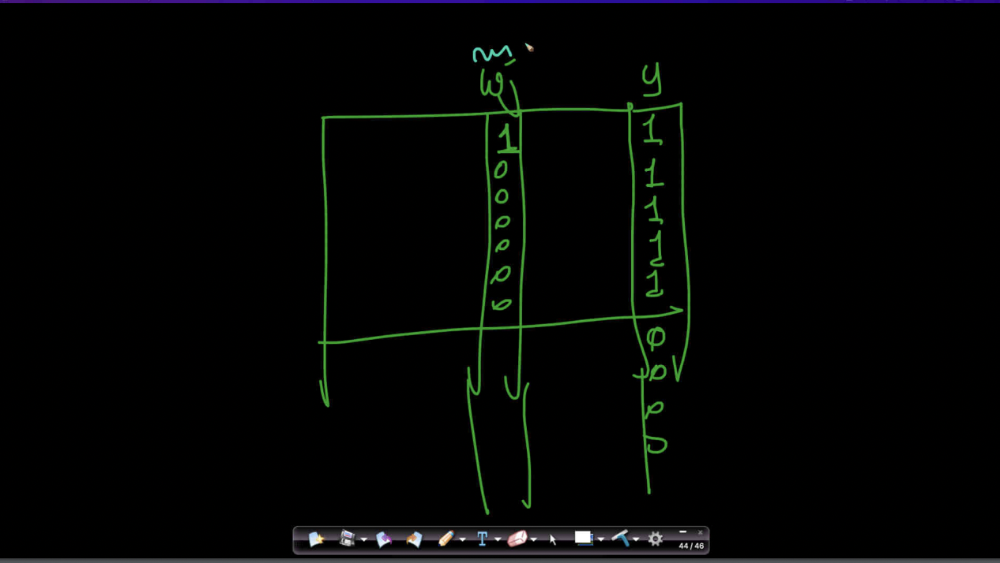


#### Q. Will we consider this word $w_j$ as outlier in training time?

This means that word $w_j$ can be a **rare word** or a **noise** in the training data.

Hence we can consider the word $w_j$ as outlier.

<br>

####** Q. How can we handle the outlier in training time ?**

Using Laplace smoothing with a slightly **larger α**.


**Note:** do not make α too large (like 10,000) as it can lead to underfitting

#### Question: Can we create different laplace smoothing constant (α) for each of the d words ?
- Theoritically we can create

- But if we had d = 10000 , then tuning of hyperparameters ($α_1,α_2,....α_10000$) becomes very hard

Hence practically we fix a single constant α for all the d words.


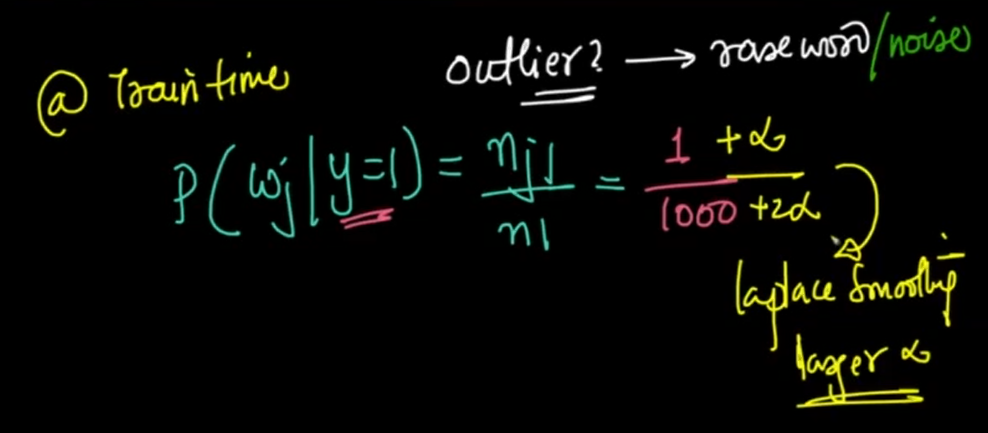

**We have another way to handle the outlier**

- if we check and see if the word $w_j$ occurs more than a **certain threshold**, (say 10),
- only then we consider the word $(w_j)$ in the likelihood calculation

Note: We should use the laplace smoothing approach than this hack,
- Since if we just increase our $\alpha$, we will. behandling the  outlier  

Because, if a word occurs less than the threshold, then instead of making $n_{j1} = 0$,
- just increasing the α, and we will deal with the outliers for both training and testing time.


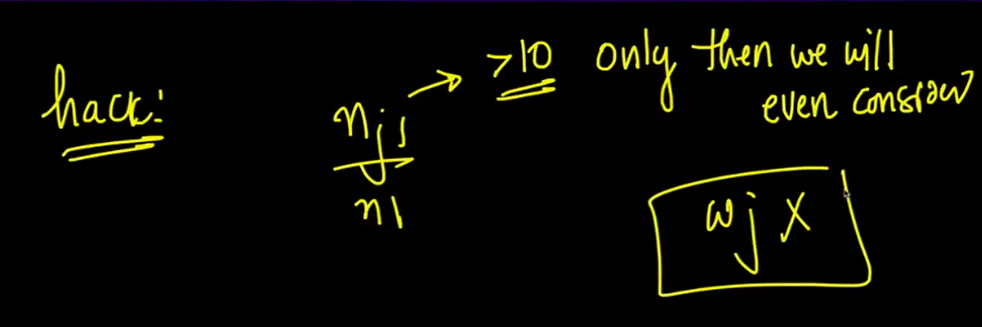

## **Multinomial Naive Bayes** [Timestamp @1:20:00]

If we see Bernouli Naive bayes have features or words of the text as 0 or 1
- where value of 1 for a word $w_j$ meaning that the word exists in the text

<br>

#### But now if we need to find how many times the $w_j$ occurs in the text_i. How can we store this information ?
This is where we use another version of Naive Bayes which is Multinomial Naive Bayes

Now instead of storing whether the word $w_j$ exists in $text_i$, we store the number of times the word $w_j$ occurs

<br>

#### Lets say $w_j$ occurs 3 times, then how will we compute the likelihood for the word $w_j$ ?
Likelihood will be the number of times the word $w_j$ has occured 3 times in all the samples of the data when y=1
 - $P(w_j=3|y=1)$

This means if w_j has values {1,2,3,4,5...k} for the entire sample of the dataset,
- we have to compute the likelihood of the word $w_j$ for each of these k-1 values
- while in Bernouli, the likelihood of the word $w_j$ will be only for the 2 values (w_j = 0 or w_j = 1)


Hence making Multinominal Naive Bayes slightly **computational costly** than Bernouli Naive bayes

<br>

#### Q. Why use Multinomial Naive Bayes if its computationally expensive ?
 It stores more information about the word in each of the texts present in the dataset.


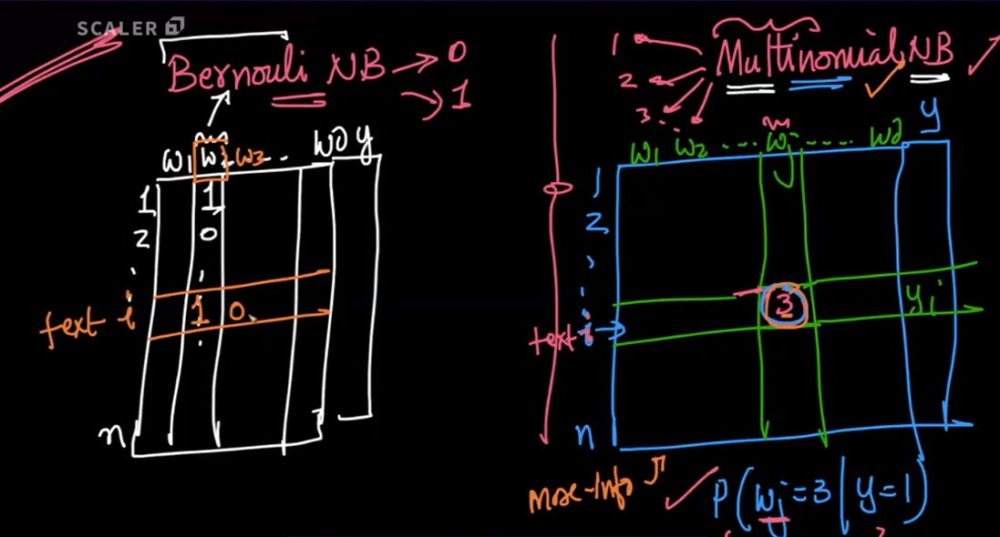

Lets generalize on what all we need when finding $P(y=1|w_1,....w_d)$ and $P(y=0|w_1,....w_d)$ for Naive Bayes models:


1. Class priors for $y=1$ and $y=0$ which our defined as:
 - $P(y=1)$ and $P(y=0)$

2. Likelihoods of each of the d word, which is the propability of the word $w_j$ occuring C times in the text when $y=1$ or $y=0$. Defined as:

  - $P(w_j=C |y=1)$ and  $P(w_j=C |y=0)$

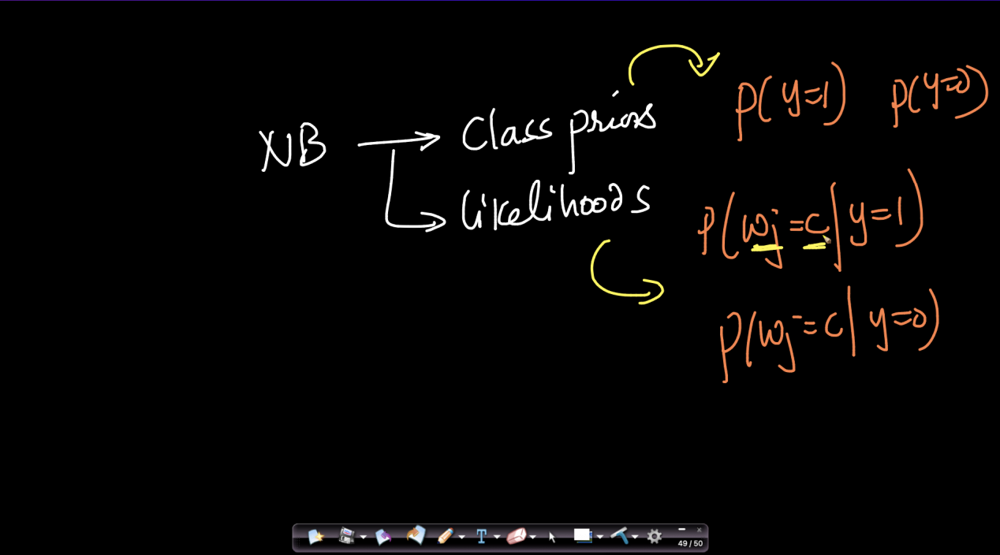

# Code

Lets implement Naive Bayes on our Spam and Ham dataset

Now to find the count of each word in the text,  we use  [CountVectorizer()](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
- that vectorizes the words with the counts of occurences of words in a given text i.

<br>

#### Q. Will this matrix be dense or sparse?
Across all the text messages, there may be thousands of words i.e. thousands of features. But any given text would only have a handful of words.

So, naturally, the value for only some of these features would be non-zero.

As a result, we get a **sparse matrix** indicating the counts of the few words that do exist out of the thousands of words.

<br>

#### Q. Should we train the CountVectorizer() on the entire dataset?
No, only train the CountVectorizer() on training data and use the parameters value to convert the test data

<br>

#### Q. Do we need to standardize data for Naive Bayes?
**No.**

Since Naive Bayes is **not a distane based algorithm**, but rather an **information based algorithm**.

Hence scaling does not help to converge it faster.

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/16748/

- https://www.scaler.com/hire/test/problem/25985/

- https://www.scaler.com/hire/test/problem/16747/ (Missing Value Question)

CODING QUESTION
- https://www.scaler.com/hire/test/problem/26055/

In [ ]:
from sklearn import feature_extraction, naive_bayes, metrics

#Count Vectorizer
f = feature_extraction.text.CountVectorizer()

X_train = f.fit_transform(df_X_train)
X_test = f.transform(df_X_test)

print(X_train.shape,X_test.shape)


(4179, 7615) (1393, 7615)


Taking different values of Laplace Smoothing constant

In [ ]:
params = {
        'alpha':[0.01, 0.1, 1, 10]
        }

We plug in the following values into our `GridSearchCV()` function to get the results:-
- Multinomial NB classifier,
- dictionary containing the range of values we wish to try for our hyperparameter,
- scoring metric
- number of folds for the cross validation set


Since data is Imbalanced, we use F-1 score as evaluation metrics

**ASSESSMENTS COVERED**
- https://www.scaler.com/hire/test/problem/23530/

In [ ]:
# Multinomial NB

from sklearn.model_selection import GridSearchCV

mnb = naive_bayes.MultinomialNB()
clf = GridSearchCV(mnb, params, scoring = "f1", cv=3)

clf.fit(X_train, y_train)

res = clf.cv_results_

for i in range(len(res["params"])):
  print(f"Parameters:{res['params'][i]} Mean_score: {res['mean_test_score'][i]} Rank: {res['rank_test_score'][i]}")



Parameters:{'alpha': 0.01} Mean_score: 0.8937240112174837 Rank: 2
Parameters:{'alpha': 0.1} Mean_score: 0.8896934746467164 Rank: 3
Parameters:{'alpha': 1} Mean_score: 0.9022297472053865 Rank: 1
Parameters:{'alpha': 10} Mean_score: 0.8603433402346446 Rank: 4


As you can see, we get the best performance when $α=1$, with F1- score of 0.9,

Now implementing this Naive Bayes on test Data

In [ ]:

mnb = naive_bayes.MultinomialNB()
mnb.fit(X_train, y_train)

y_pred = mnb.predict(X_test)

print(metrics.f1_score(y_test,y_pred))


0.9214092140921409


We see how Multinomial Naive Bayes achieved f-1 score of 0.92 even when data is imbalanced.
- showing how Mulitnomial Naive Bayes is not much effected by the class priors

# TODO:  Predict for 1 sentence

In [ ]:
"Nigeran price needs your help. Send money"